# 2-motor: bemf-coast

Measure the motor's back-EMF constant from the terminal voltage of the coasting rotor over its speed, with the speed counted in the commutation ripple of the same samples, so every speed read from the terminals later rests on a number taken with no current in the winding.

## Purpose

A brushed DC motor turning at a speed $\omega$ puts a voltage $e = K_e \, \omega$ across its terminals, the back-EMF, and $K_e$ is the back-EMF constant in volt seconds per radian. The same constant is the torque per amp, $K_t = K_e$ in SI units, so it ties the current to the torque as well. Stage 3 reads the motor's speed from the terminals in situ through $K_e$, stage 4 builds the speed estimator on it, and the no-load-current experiment of this stage turns the spin's current into a drag torque through it. A motor has no datasheet, so the number has to be measured, and the cleanest place to measure it is the bare motor with nothing between the terminals and the board.

The route is the open-circuit one. The motor is spun at a duty, then the bridge is opened and the rotor coasts. With both bridge legs off the winding carries no current, so the terminal voltage is the EMF itself with no resistive drop to take out, and the EMF carries the commutation ripple, $N_r$ events per revolution, which counts the speed in the same samples. Nothing outside the board is needed. A second route reads the EMF at the cut over the speed the spin's current ripple counts, and the two are compared cycle by cycle. The coast route is the one the result file carries. Over the duties and the two rail levels the cycles span a range of speeds, and whether one $K_e$ holds across that range, across the directions and across the levels is part of what gets settled.

## Procedure

`capture.py` runs cycles of a spin and a coast. A cycle is one `osc sweep` with the schedule `D@1500,coast:800` in both directions. It records a half second torque-off rest, then 1.5 s at the duty $D$ forward, then 0.8 s with the bridge open and the rotor coasting, then the same pair in reverse. The coast is chained to its spin with no settle between them, so the rotor goes from the drive into the coast at speed. The spin is long enough for the speed to settle, which an earlier run with a 300 ms spin did not give, and the Method shows what the settle looks like in the current's tail. The duties are 15, 20, 30, 40 and 60 %, three cycles each, at rail levels of 5.0 and 7.4 V, thirty cycles in all, with at least twenty seconds of rest between cycles, the bench rule for a bare motor. A cycle started every 75 s or so, the sweep's own rests and the script's hold together.

1. The bare motor in the rig, its two leads on the board's motor connector, the wrench bar off the pinion so the rotor is free. The board on the DPS, the adapter on the bus at 3 Mbps. The board runs the experiment image, so the cycles are open loop with only the raw current trip and the bus dead-man as protections.
2. `capture.py`. The DPS comes on before the board's leads go on, because its output comes up at its previous setting for a moment. The script then trims the DPS until the board's own rail tap reads each level, and runs the fifteen cycles of that level.

The levels name the rail, VSYS. The dev board has a feed diode, so the DPS is trimmed over it until the rail reads the level, and the trim reads the rail through the chip's own 1.2 V reference.

## Data

One folder under the capture.

- `cycles.csv`: one row per cycle. `k` the cycle number, `volts_set` the rail level asked for, `dps_read` the DPS output that reached it, `vsys_read` the rail the board read at rest before the level's cycles, `duty_pct` the spin duty, `repeat` 0 to 2, `t_start` and `t_end` the host time the sweep ran, `folder` the cycle's folder.
- `cycles/K/sweep.csv`, `meta.json`: the rest, the two spins and the two coasts of one cycle, one row per control tick at 20 kHz. Segment 0 is the rest, 1 the forward spin, 2 the coast chained to it, 3 and 4 the same in reverse. `cmd_duty_q15` is the commanded duty, 0 in a coast, `dir` the direction, `duty_counts` the applied window in timer ticks, 0 from the cut on. `current_raw`, `vmotor_a`, `vmotor_b`, `vbus_raw` and `ntc_raw` are ADC counts. `tick` restarts at 0 in every segment, and a jump in it is a dropped frame. Each segment is its own stream from the board, and the rows between the end of a spin's stream and the start of its coast's stream, while the host commits the zero duty, are not recorded.

### cycles.csv

The rail asked for and the duty of every cycle, in the order they ran.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

from oscnb import boards, motors, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colors
MOTOR = motors.MOTORS[motors.DEFAULT]                                   # the motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "bemf-coast" / "capture-1").resolve()
COLOR = {5.0: BLUE, 7.4: ORANGE}                                        # one color per rail level, fixed through the notebook
MARK = {1: "o", -1: "^"}                                                # the direction as the marker shape, forward filled, reverse open
FS = BOARD.tick_hz                                                      # rows per second, the control rate
N_R = MOTOR.ripple_per_rev                                              # commutation events per revolution, slots x brushes
print(MOTOR.key, "on", BOARD.key, "from", results.rel(CAPTURE))
print(f"{MOTOR.slots} slots x {MOTOR.brushes} brushes = {N_R} ripple events per revolution; rows at {FS} Hz")

mg90-b on dev-v006-2A-D from telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1
3 slots x 2 brushes = 6 ripple events per revolution; rows at 20000 Hz


,k,volts_set,dps_read,vsys_read,duty_pct,repeat,t_start,t_end,folder,trim_mv
0,0,5.000,5.250,4.993,15,0,1793217180.361,1793217235.011,cycles/0,-7.000
1,1,5.000,5.250,4.993,15,1,1793217255.016,1793217309.752,cycles/1,-7.000
2,2,5.000,5.250,4.993,15,2,1793217329.758,1793217384.650,cycles/2,-7.000
3,3,5.000,5.250,4.993,20,0,1793217404.655,1793217459.436,cycles/3,-7.000
4,4,5.000,5.250,4.993,20,1,1793217479.441,1793217533.480,cycles/4,-7.000
5,5,5.000,5.250,4.993,20,2,1793217553.485,1793217607.551,cycles/5,-7.000
6,6,5.000,5.250,4.993,30,0,1793217627.556,1793217681.794,cycles/6,-7.000
7,7,5.000,5.250,4.993,30,1,1793217701.799,1793217756.612,cycles/7,-7.000
8,8,5.000,5.250,4.993,30,2,1793217776.617,1793217831.430,cycles/8,-7.000
9,9,5.000,5.250,4.993,40,0,1793217851.435,1793217906.121,cycles/9,-7.000


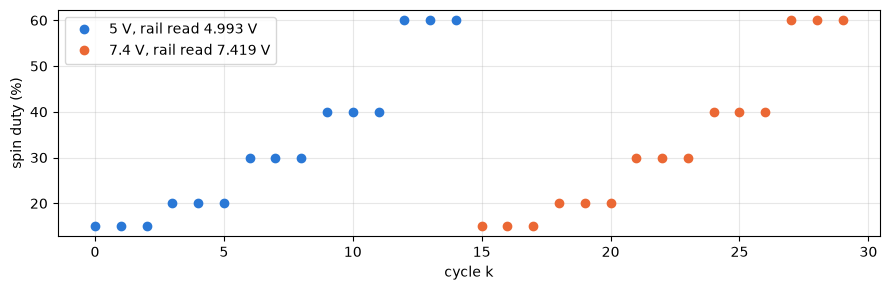

30 cycles, 2219 s from the first sweep to the end of the last


In [2]:
cycles = pd.read_csv(CAPTURE / "cycles.csv")
cycles["trim_mv"] = (cycles["vsys_read"] - cycles["volts_set"]) * 1e3   # how far the trim landed from the level
show(cycles, n=None)
fig, ax = plt.subplots(figsize=(9, 3))
for v, g in cycles.groupby("volts_set"):
    ax.plot(g["k"], g["duty_pct"], "o", color=COLOR[v], label=f"{v:g} V, rail read {g['vsys_read'].iloc[0]:.3f} V")   # one dot per cycle
ax.set_xlabel("cycle k"); ax.set_ylabel("spin duty (%)"); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"{len(cycles)} cycles, {cycles['t_end'].iloc[-1] - cycles['t_start'].iloc[0]:.0f} s from the first sweep to the end of the last")

The duty ladder at each level, three cycles per duty, with the rail the board read before each level's cycles in the legend. The 5.0 V level landed 7 mV under its level and the 7.4 V level 19 mV over it, read once at rest before each level. Both are small against anything this notebook reads, since the EMF of a coast does not depend on the rail.

### cycles/K/sweep.csv and meta.json

One cycle, the first 30 % cycle at 5.0 V. The current channel, the two terminal taps and the applied duty over the rest, the two spins and the two coasts, then a close look at the cut.

cycle 6 | segments: {0: 10000, 1: 30000, 2: 16000, 3: 30000, 4: 16000} | schedule: ['30@1500', 'coast:800'] | dirs: [1, -1] | baseline ms: 500 | decay: slow | rows dropped: 0


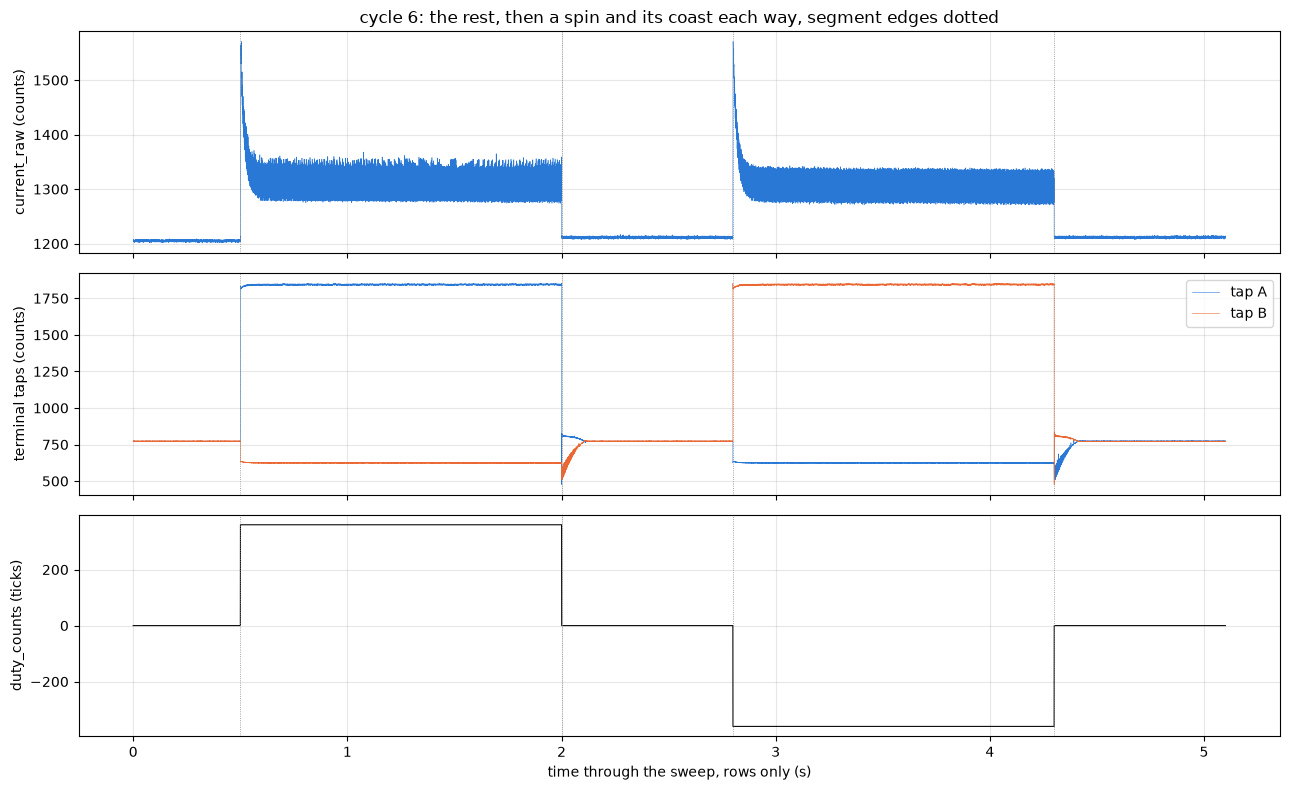

In [3]:
def cycle_folder(k):
    return CAPTURE / cycles.loc[cycles["k"] == k, "folder"].iloc[0]

def pairs(df):
    # (direction, spin rows, coast rows) for every spin and the coast chained to it: a coast is a
    # driven segment with a zero command, and its spin is the segment before it
    out = []
    for seg, co in df[df["seg"] > 0].groupby("seg"):
        if int(co["cmd_duty_q15"].iloc[0]) != 0:
            continue
        sp = df[df["seg"] == seg - 1]
        out.append((int(co["dir"].iloc[0]), sp, co))
    return out

def cut_row(co):
    # the cut: the first row of the coast's stream with no drive, the rows before it being the drive's tail
    z = np.flatnonzero(co["duty_counts"].to_numpy() == 0)
    return int(z[0]) if len(z) else None

K_SHOW = int(cycles[(cycles["volts_set"] == 5.0) & (cycles["duty_pct"] == 30)]["k"].iloc[0])
df, meta = tel.load(cycle_folder(K_SHOW), BOARD)      # checks the sense block against the board entry
print("cycle", K_SHOW, "| segments:", df["seg"].value_counts().sort_index().to_dict(), "| schedule:", meta["schedule"],
      "| dirs:", meta["dirs"], "| baseline ms:", meta["baseline_ms"], "| decay:", meta["decay"], "| rows dropped:", meta["rows_dropped"])
SPIN_LEN_MS = len(pairs(df)[0][1]) / FS * 1e3          # the spin's length in ms, from its rows
ts = np.arange(len(df)) / FS                           # time through the sweep as rows, since `tick` restarts at each segment
edges = np.flatnonzero(np.diff(df["seg"].to_numpy()) != 0) + 1
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
ax[0].plot(ts, df["current_raw"], lw=0.4, color=BLUE); ax[0].set_ylabel("current_raw (counts)")
ax[1].plot(ts, df["vmotor_a"], lw=0.4, color=BLUE, label="tap A"); ax[1].plot(ts, df["vmotor_b"], lw=0.4, color=ORANGE, label="tap B")
ax[1].set_ylabel("terminal taps (counts)"); ax[1].legend(loc="upper right")
ax[2].plot(ts, df["duty_counts"], lw=0.8, color=INK); ax[2].set_ylabel("duty_counts (ticks)"); ax[2].set_xlabel("time through the sweep, rows only (s)")
for a in ax:
    for e in edges:
        a.axvline(e / FS, color=MUTED, lw=0.6, ls=":")   # segment edges, where the streams meet
    a.grid(alpha=0.3)
ax[0].set_title(f"cycle {K_SHOW}: the rest, then a spin and its coast each way, segment edges dotted")
plt.tight_layout(); plt.show()

The current steps up with the spin, with a start-up peak of about 1570 counts that falls away in the first 100 ms, and drops back near the rest zero in the coast. The taps swap with the direction and come back together through each coast, and the duty shows the two spins and the two coasts as four flat stretches. The rows between the segments are not recorded, so the streams sit end to end here.

The current in each coast sits a few counts above the torque-off rest before the spin. That is the bridge being awake with its outputs open, and it gets its own section in the Results.

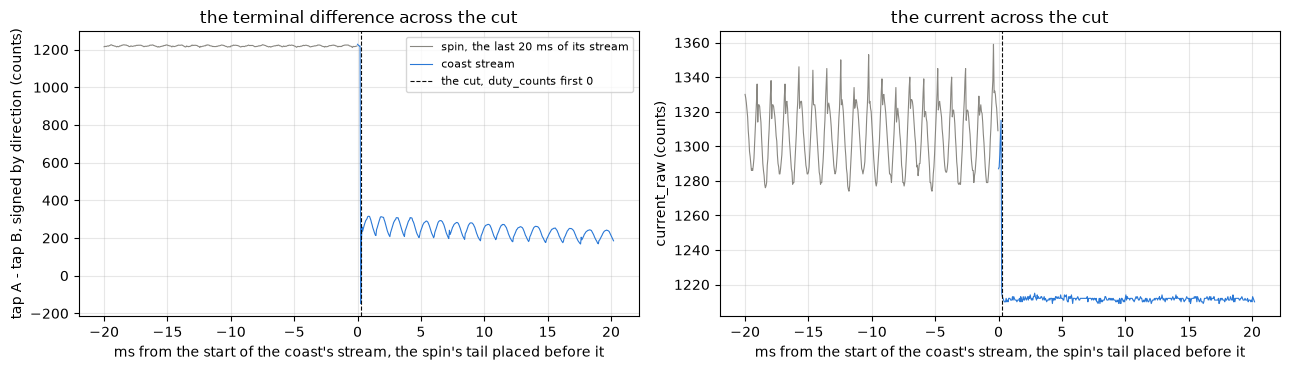

direction +1: the coast's stream opens with 5 rows of drive before the cut; the coast holds 15995 rows past it, 0.800 s


In [4]:
d, sp, co = pairs(df)[0]
z = cut_row(co)
tail, head = sp.iloc[-400:], co.iloc[:z + 400]        # the last 20 ms of the spin's stream, the first 20 ms past the cut
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(np.arange(-len(tail), 0) / FS * 1e3, (tail["vmotor_a"] - tail["vmotor_b"]) * d, lw=0.8, color=MUTED, label="spin, the last 20 ms of its stream")
ax[0].plot(np.arange(len(head)) / FS * 1e3, (head["vmotor_a"] - head["vmotor_b"]) * d, lw=0.8, color=BLUE, label="coast stream")
ax[0].axvline(z / FS * 1e3, color=INK, lw=0.8, ls="--", label="the cut, duty_counts first 0")
ax[0].set_ylabel("tap A - tap B, signed by direction (counts)"); ax[0].legend(fontsize=8); ax[0].set_title("the terminal difference across the cut")
ax[1].plot(np.arange(-len(tail), 0) / FS * 1e3, tail["current_raw"], lw=0.8, color=MUTED); ax[1].plot(np.arange(len(head)) / FS * 1e3, head["current_raw"], lw=0.8, color=BLUE)
ax[1].axvline(z / FS * 1e3, color=INK, lw=0.8, ls="--"); ax[1].set_ylabel("current_raw (counts)"); ax[1].set_title("the current across the cut")
for a in ax:
    a.set_xlabel("ms from the start of the coast's stream, the spin's tail placed before it"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"direction {d:+d}: the coast's stream opens with {z} rows of drive before the cut; the coast holds {len(co) - z} rows past it, {(len(co) - z) / FS:.3f} s")

Under drive the difference reads the rail at the crest sample and the current carries the ripple. From the cut the difference drops to the EMF and starts to decay, with the same ripple on it, and the current falls to the open bridge's zero within a row or two. The coast's stream opens with a few rows of drive, 2 to 9 across the capture, so the cut is found in each coast and not assumed at its first row. The gap between the two streams is not drawn, the spin's tail is just placed before the coast's stream.

## Raw traces

Every coast's terminal difference from its cut, one panel per level, light to dark with the spin duty, so the decays can be compared across duties and the repeats seen on top of each other. The axis stops at 320 ms, since every rotor has stopped well before the 800 ms coast ends.

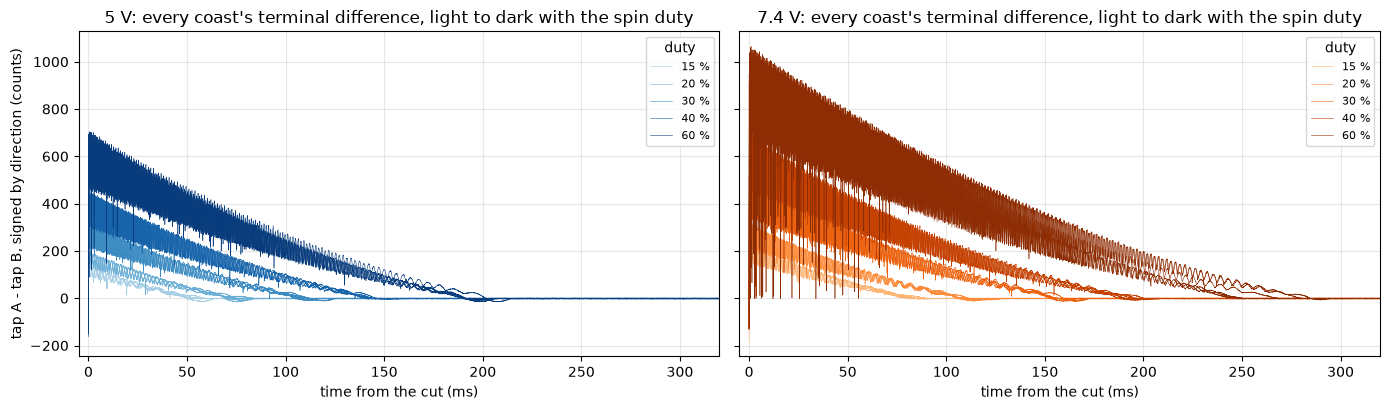

missing rows per cycle: none


In [5]:
DUTIES = sorted(cycles["duty_pct"].unique())
SHADE = {v: dict(zip(DUTIES, (plt.cm.Blues if v == 5.0 else plt.cm.Oranges)(np.linspace(0.35, 0.95, len(DUTIES))))) for v in COLOR}   # one hue per level, light to dark with the duty
missing = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for _, C in cycles.iterrows():
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    missing[int(C["k"])] = int(tel.gaps(df).sum())                      # rows lost between the board and the host, by the tick count
    a = ax[0] if C["volts_set"] == 5.0 else ax[1]
    for d, sp, co in pairs(df):
        z = cut_row(co)
        if z is None:
            continue
        e = ((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:]   # the tap difference from the cut, signed so the EMF reads positive
        a.plot(np.arange(len(e)) / FS * 1e3, e, lw=0.4, color=SHADE[C["volts_set"]][C["duty_pct"]], label=f"{C['duty_pct']} %" if C["repeat"] == 0 and d == 1 else None)
for a, v in zip(ax, COLOR):
    a.set_title(f"{v:g} V: every coast's terminal difference, light to dark with the spin duty"); a.set_xlabel("time from the cut (ms)")
    a.set_xlim(-5, 320)                                                  # every rotor has stopped well before the 800 ms coast ends
    a.grid(alpha=0.3); a.legend(fontsize=8, title="duty")
ax[0].set_ylabel("tap A - tap B, signed by direction (counts)")
plt.tight_layout(); plt.show()
print("missing rows per cycle:", {k: m for k, m in missing.items() if m} or "none")

Each coast starts at the EMF its spin reached and falls to zero along something close to a straight line. A straight line says the drag on the free rotor is most likely a constant torque for the most part, with only a little of it growing with speed. The no-load-current notebook fits that. The rotor stops 45 to 52 ms after the cut from 15 % at 5.0 V and 239 to 281 ms after it from 60 % at 7.4 V, so the 0.8 s coast is mostly a rotor at rest with the bridge still open, and the slowest coasts are short. The three repeats of each duty lie on top of each other and no rows are missing.

Two things in these traces are not plain decay. At the higher duties a few coasts drop to zero for a single row and come straight back, the thin spikes down to the axis in the 7.4 V panel. Those get a section of their own below. And near the stop some traces swing a few counts below zero before they settle, which looks like the rotor rocking back on the magnets' pull after it stops. That part of the coast is under the count's floor and nothing here reads it.

## Method

Two symbols carry the notebook. $\omega$ is the motor's speed in radians per second, and $K_e$ the back-EMF constant, so that the open-circuit terminal voltage is $e = K_e \, \omega$. The speed is never read from an outside instrument here. It is counted in the ripple. A brushed motor with $N_r$ commutation events per revolution, 3 slots times 2 brushes for this one, puts a ripple at $f_r = N_r \, \omega / 2\pi$ hertz on its current under drive and on its terminal voltage when it coasts, so a count of the ripple's cycles over a known time is a speed, with the parts count as the only constant.

Every cycle goes through the same reduction, once per direction.

1. The rest. The second half of the torque-off segment gives the current channel's zero and the taps' difference at rest, with no EMF and no current. Both are the cycle's own.
2. The spin window, the last 200 ms of the spin's stream. The current over the rest zero and the stage 1 in-drive offset, converted through the current-scale result. The applied duty, the rail and the driven terminal level. The spin's speed, counted in the current's ripple over the window. And how often the current drops out, a row whose current over the zero is under a quarter of the window's mean.
3. The coast, from the cut, the first row of the coast's stream whose applied duty is zero. The terminal difference signed by the direction, less the rest difference, converted through the terminal-chain result, is the EMF $e(t)$. A cycle turned if the EMF 0.1 to 1 ms past the cut is at least 0.05 V.
4. The open rows. A coast row whose EMF falls under 30 % of the mean of the 2 ms around it, while that mean is still over 0.05 V, is taken as a moment the brush path was open, and is bridged with a line between its neighbors. The section on these rows below shows what they are. The coast route is read both ways, with the open rows bridged and as read.
5. The coast's window. The strongest line in the spectrum of the EMF 1 to 11 ms past the cut seeds the count. The window is then the whole number of ripple cycles closest to 10 ms, and never fewer than three, starting at an upward crossing just after 1 ms past the cut. The crossings are those of the EMF through a band-pass of +/-35 % around the window's own mean frequency, run forward and back so it shifts no crossing in time, and found by repeating the count until the frequency stops moving. The band-pass runs over a stretch three cycles longer than the window plus a margin, so no crossing the window uses sits at the filter's edge.
6. The coast route. The window's mean EMF over the speed its crossings count,

$$K_e = \frac{\overline{e}}{\omega} = \frac{\overline{e} \, N_r}{2\pi \, f_r}$$

with the mean and the count taken over the same rows. No current flows, so there is no $R \, i$ to take out and no resistance to know. Whole cycles keep the ripple out of the mean.

7. $E_0$, the EMF at the cut, is a line through the one-ripple boxcar of the EMF over the window, extrapolated back to the cut, and its slope is the deceleration the no-load-current experiment reads.
8. The spin route. $E_0$ over the spin window's counted speed. This assumes the speed does not move between the window and the cut, which the gap between the streams does not let the data check directly, so the paired difference of the two routes is the check.

The window is the main change from the plan made before the data came in, which read a fixed 10 ms and ran the band-pass over those 10 ms alone. The 15 % coasts at 5.0 V stop in about 50 ms and hold about three ripple cycles in their first 10 ms. The filter's edge took two of those three crossings, and four of the six coasts at that duty gave no count at all. A window of whole cycles with the filter run past it keeps every coast.

The decay inside the window does not bias the ratio. A count of whole cycles over the time they took is the mean frequency over that time, and the EMF's mean over the same rows is its mean over the same time. So the ratio of the two is $K_e$ as long as $K_e$ is the same at every speed the window passes through. Stepping the same window down the whole coast, end to end, reads $K_e$ at every speed the rotor passes through and shows whether it is the same.

The spin's count is seeded by the coast's line and band-passed around it. Under drive the current can carry a line at half the ripple frequency, three events per revolution, that is stronger than the six-per-revolution line at the higher duties, and a free peak search would land on it and halve the speed. The seed keeps the count on the same line the coast reads. The frequency a free peak search picks is kept beside the count, with the height of the half line over the full line, so the reduction shows where the two part.

The spin is 1.5 s so the speed has settled when the window is read. The settle is shown rather than assumed. The spin's current in 50 ms bins, with the speed counted in the same bins from 100 ms on, says how the rotor approached its steady speed, and the change of both across the 200 ms window says how settled the window is. The plan fitted an exponential to the tail from 300 ms on, and on this data the fit ran into one of its bounds on the time constant, 10 ms or 5 s, on 11 of the 60 spins, since the current keeps sliding slowly to the end of the spin and the tail has no single time constant to find. The change across the window answers the question directly. The no-load-current experiment reads the same window for the drag, so the settle is its margin as much as this experiment's.

### Stage 1 values carried in

In [6]:
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)     # the taps' and the rail's counts per volt against the meter
CS = results.read("1-board", "current-scale", pair=BOARD.key)      # the current chain's counts per amp and its in-drive offset
RN = results.read("1-board", "rest-noise", pair=BOARD.key)         # the taps' floor at rest
V_PER_COUNT = 1 / TC["terminal_counts_per_v"]["value"]              # volts of terminal difference per count
A_PER_COUNT = 1 / CS["counts_per_a"]["value"]                        # amps per count over the zero
I_DRIVE_OFFSET = CS["drive_offset_counts"]["value"]                 # counts the chain reads over its rest zero whenever the bridge is active
rail_v = lambda n: (np.asarray(n, float) - TC["rail_offset_counts"]["value"]) / TC["rail_counts_per_v"]["value"]
tap_floor = np.hypot(RN["tap_a_noise"]["value"], RN["tap_b_noise"]["value"])   # one row of difference, both taps' floors added in quadrature
print(f"terminal difference {TC['terminal_counts_per_v']['value']:.2f} counts/V ({TC['terminal_counts_per_v']['lo']:.2f} to {TC['terminal_counts_per_v']['hi']:.2f}), "
      f"{V_PER_COUNT * 1e3:.3f} mV per count, {(TC['terminal_counts_per_v']['value'] * BOARD.v_term_per_count - 1) * 100:+.2f} % over the nominal")
print(f"current {CS['counts_per_a']['value']:.1f} counts/A ({CS['counts_per_a']['lo']:.1f} to {CS['counts_per_a']['hi']:.1f}), in-drive offset {I_DRIVE_OFFSET:+.1f} counts, "
      f"graded on DC over {CS['amps_range']['lo']:.2f} to {CS['amps_range']['hi']:.2f} A")
print(f"rail {TC['rail_counts_per_v']['value']:.2f} counts/V at rest, offset {TC['rail_offset_counts']['value']:.1f} counts")
print(f"taps at rest {RN['tap_a_noise']['value']:.2f} and {RN['tap_b_noise']['value']:.2f} counts rms, so one row of difference carries about {tap_floor * V_PER_COUNT * 1e3:.1f} mV of noise")

terminal difference 248.37 counts/V (248.20 to 248.53), 4.026 mV per count, +0.05 % over the nominal
current 1135.0 counts/A (1133.8 to 1136.3), in-drive offset +5.3 counts, graded on DC over 0.23 to 1.31 A
rail 247.54 counts/V at rest, offset 6.0 counts
taps at rest 0.61 and 0.65 counts rms, so one row of difference carries about 3.6 mV of noise


The terminal difference reads 248.37 counts per volt, 0.05 % over the nominal, so a count is 4.03 mV of EMF. One row of difference carries about 3.6 mV of noise at rest, 1 % of the slowest window's 0.35 V for a single row and far less for a window's mean of a hundred rows or more. The current chain's in-drive offset of +5.3 counts was graded under DC drive at 100 % duty, and the spins here switch at 15 to 60 %.

### The per-cycle reduction

Every cycle through the steps above, one row per direction.

In [7]:
SPIN_MS = 200                      # the spin window: the last 200 ms of the spin's stream, where the speed has settled
COAST_FROM = 20                    # rows past the cut the coast's read starts, 1 ms, after the taps settle
TARGET_MS = 10                     # the coast's read spans the whole number of ripple cycles closest to this
MIN_CYCLES = 3                     # and never fewer than this, which the slowest coasts need
TURN_V = 0.05                      # a coast whose EMF 0.1 to 1 ms past the cut is under this did not turn
BAND = (150.0, 6000.0)             # Hz, where a ripple line is looked for
NBH = 41                           # rows, about 2 ms, the neighborhood an EMF row is compared with
OPEN_FRAC = 0.3                    # a coast row under this share of its neighborhood's mean is an open brush path
SPIN_OPEN_FRAC = 0.25              # a spin row whose current over the zero is under this share of the window's mean is the same
TAIL_FROM = 10_000                 # rows past the cut, 0.5 s: the rotor has stopped and the bridge is still open

def spectrum(x):
    # the Hann-windowed amplitude spectrum, zero-padded 8x, and its frequencies
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    return np.fft.rfftfreq(8 * n, 1 / FS), np.abs(np.fft.rfft(x * np.hanning(n), 8 * n))

def line_freq(x, lo=BAND[0], hi=BAND[1]):
    # the frequency of the strongest line in [lo, hi] Hz, what a free peak picker reads
    f, X = spectrum(x)
    m = (f >= lo) & (f <= hi)
    return float(f[m][int(np.argmax(X[m]))])

def line_height(x, f0, frac=0.1):
    # the tallest point of the spectrum within f0 x (1 +/- frac)
    f, X = spectrum(x)
    m = (f >= f0 * (1 - frac)) & (f <= f0 * (1 + frac))
    return float(X[m].max())

def crossings(x, f0, frac=0.35):
    # the upward zero crossings of the line near f0, in rows from the start of x and interpolated to a fraction of a row:
    # a second-order band-pass f0 x (1 +/- frac) run forward and back, so it shifts no crossing in time, and the first
    # and last crossing dropped as the filter's edge
    hi = min(f0 * (1 + frac), 0.95 * FS / 2)
    sos = butter(2, [f0 * (1 - frac), hi], btype="band", fs=FS, output="sos")
    y = sosfiltfilt(sos, np.asarray(x, float) - np.mean(x))
    s = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
    return (s + (-y[s]) / (y[s + 1] - y[s]))[1:-1]

def count_cycles(x, f0, frac=0.35):
    # (mean frequency, cycles) over every whole cycle of the line near f0 in x, for a stretch whose speed is steady
    tc = crossings(x, f0, frac)
    if len(tc) < 3:
        return np.nan, 0
    return (len(tc) - 1) / ((tc[-1] - tc[0]) / FS), len(tc) - 1

def read_window(e, start, f_seed, target_ms=TARGET_MS):
    # (mean frequency, first row, last row, cycles) over the whole ripple cycles from `start` closest to target_ms, at
    # least MIN_CYCLES. The band-pass runs over a stretch three cycles and a margin longer than the window, so the
    # window's crossings are never the filter's edge, and its band is centered on the window's own mean frequency,
    # found by repeating the count, since the rotor slows through the window.
    f = f_seed
    for _ in range(6):
        n = max(MIN_CYCLES, int(round(target_ms / 1e3 * f)))           # cycles in the window at the current estimate
        stop = start + int((n + 3) * FS / f * 1.3)                       # the stretch the filter runs over
        if stop > len(e):
            return np.nan, 0, 0, 0
        tc = crossings(e[start:stop], f)
        if len(tc) < n + 1:
            return np.nan, 0, 0, 0
        tc = tc[:n + 1]                                                  # the window: n whole cycles from the first crossing
        f_new = n / ((tc[-1] - tc[0]) / FS)
        done = abs(f_new / f - 1) < 1e-4
        f = f_new
        if done:
            break
    return f, start + int(np.ceil(tc[0])), start + int(np.floor(tc[-1])), n

def open_rows(e):
    # rows where the EMF falls under OPEN_FRAC of its neighborhood while the rotor still turns, past the first 1 ms
    ref = np.convolve(e, np.ones(NBH) / NBH, mode="same")
    bad = (e < OPEN_FRAC * ref) & (ref > TURN_V)
    bad[:COAST_FROM] = False
    return bad

def bridge(e, bad):
    # the EMF with each open row replaced by a line between its neighbors, the EMF the winding carried while the path was open
    if not bad.any():
        return e.copy()
    x = np.arange(len(e))
    out = e.copy()
    out[bad] = np.interp(x[bad], x[~bad], e[~bad])
    return out

def coast_emf(co, d, z, zero_e):
    # the EMF in volts from the cut: the tap difference signed by the direction, less the rest difference, through the stage 1 scale
    return (((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:] - zero_e) * V_PER_COUNT

def reduce_cycle(C):
    # one cycle through the reduction, one row per direction
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    rest = tel.baseline(df)
    zero_i = rest["current_raw"].median()                             # the current channel's own rest zero
    zero_e = (rest["vmotor_a"] - rest["vmotor_b"]).median()            # the tap difference at rest, no EMF and no current
    rows = []
    for d, sp, co in pairs(df):
        row = {"k": int(C["k"]), "level": float(C["volts_set"]), "duty": int(C["duty_pct"]), "repeat": int(C["repeat"]), "dir": d,
               "missing": int(tel.gaps(df).sum())}
        # the spin window: current over the rest zero and the in-drive offset, the applied duty, the rail, the driven terminal level
        w = sp.iloc[-SPIN_MS * FS // 1000:]
        x = w["current_raw"].to_numpy(float)
        row["i_spin_a"] = (x.mean() - zero_i - I_DRIVE_OFFSET) * A_PER_COUNT
        row["i_spin_sd_a"] = x.std() * A_PER_COUNT
        over = x - zero_i - I_DRIVE_OFFSET
        row["spin_open_per_s"] = np.sum(over < SPIN_OPEN_FRAC * over.mean()) / (len(x) / FS)   # rows where the current drops out, per second
        row["duty_applied"] = float(BOARD.duty_pct_of_ticks(w["duty_counts"].abs().median()))
        row["rail_v"] = float(rail_v(w["vbus_raw"].mean()))
        row["v_on"] = ((w["vmotor_a"] - w["vmotor_b"]) * d - zero_e).mean() * V_PER_COUNT
        z = cut_row(co)
        if z is None:
            rows.append(row); continue
        e_read = coast_emf(co, d, z, zero_e)
        # the open bridge after the rotor stopped: the current channel's zero with the bridge awake and no current in the winding
        row["open_zero_counts"] = co["current_raw"].to_numpy(float)[z + TAIL_FROM:].mean() - zero_i
        row["tail_emf_v"] = e_read[TAIL_FROM:].mean()
        row["i_spin_open_zero_a"] = (x.mean() - zero_i - row["open_zero_counts"]) * A_PER_COUNT
        row["e_first_v"] = e_read[2:20].mean()
        row["turned"] = bool(row["e_first_v"] >= TURN_V)
        if not row["turned"]:
            rows.append(row); continue
        bad = open_rows(e_read)
        e = bridge(e_read, bad)
        smooth = np.convolve(e, np.ones(NBH) / NBH, mode="same")
        below = np.flatnonzero(smooth[COAST_FROM:] < TURN_V)
        row["stop_ms"] = (COAST_FROM + below[0]) / FS * 1e3 if len(below) else np.nan   # where the EMF falls under TURN_V, the rotor about stopped
        row["coast_open_rows"] = int(bad.sum())
        row["coast_open_per_s"] = bad.sum() / (row["stop_ms"] / 1e3)
        # the coast route: the window of whole cycles from 1 ms, the EMF over the same rows, open rows bridged and as read
        f_c0 = line_freq(e[COAST_FROM:COAST_FROM + 200])                  # the early coast's ripple line, the seed of both counts
        f_c, i0, i1, n_c = read_window(e, COAST_FROM, f_c0)
        row.update(f_seed=f_c0, f_coast=f_c, coast_cycles=n_c, window_ms=(i1 - i0) / FS * 1e3, emf_v=e[i0:i1].mean(),
                   emf_read_v=e_read[i0:i1].mean(), open_in_window=int(bad[i0:i1].sum()))
        # each terminal over the window, in volts from ground: the tap against the bias node, which is the same tap's reading at rest
        pos, neg = ("vmotor_a", "vmotor_b") if d == 1 else ("vmotor_b", "vmotor_a")
        win = co.iloc[z + i0:z + i1]
        row["term_pos_v"] = float(BOARD.term_v(win[pos].mean(), rest[pos].median()))
        row["term_neg_v"] = float(BOARD.term_v(win[neg].mean(), rest[neg].median()))
        row["coast_i_counts"] = win["current_raw"].mean() - zero_i - row["open_zero_counts"]   # the current channel over the window, from the open bridge's zero
        # E0: a line through the one-ripple boxcar of the EMF over the window, back to the cut, and its slope, the deceleration in volts per second
        nbox = max(int(round(FS / f_c)), 1)
        es = np.convolve(e, np.ones(nbox) / nbox, mode="same")
        t = np.arange(len(e)) / FS
        p = np.polyfit(t[i0:i1], es[i0:i1], 1)
        row.update(e0_v=float(np.polyval(p, 0.0)), dedt_v_per_s=float(p[0]))
        # the spin's speed, counted in the current's ripple over the window, seeded by the coast's line, and what a free peak reads
        f_s, n_s = count_cycles(x, f_c0)
        row.update(f_spin=f_s, spin_cycles=n_s, f_free=line_freq(x), spin_half_over_full=line_height(x, f_s / 2) / line_height(x, f_s))
        rows.append(row)
    return rows

CYC = pd.DataFrame([r for _, C in cycles.iterrows() for r in reduce_cycle(C)])
CYC["turned"] = CYC["turned"].fillna(False).astype(bool)
CYC["speed_rev_s"] = CYC["f_coast"] / N_R                      # rev/s over the coast's window
CYC["spin_speed_rev_s"] = CYC["f_spin"] / N_R                  # rev/s over the spin's window
CYC["w_coast"] = 2 * np.pi * CYC["speed_rev_s"]                # rad/s at the motor shaft, from the coast's count
CYC["w_spin"] = 2 * np.pi * CYC["spin_speed_rev_s"]            # the same from the spin's current
CYC["ke_coast"] = CYC["emf_v"] / CYC["w_coast"]                # V s/rad, no current in the winding, open rows bridged
CYC["ke_read"] = CYC["emf_read_v"] / CYC["w_coast"]            # the same with the open rows left as read
CYC["ke_spin"] = CYC["e0_v"] / CYC["w_spin"]                   # the EMF at the cut over the drive's speed
show(CYC[["k", "level", "duty", "dir", "rail_v", "i_spin_a", "spin_speed_rev_s", "spin_half_over_full", "f_free", "stop_ms", "coast_cycles", "window_ms",
          "speed_rev_s", "emf_v", "open_in_window", "ke_coast", "ke_read", "e0_v", "ke_spin"]], n=None)
print(f"{len(CYC)} spin and coast pairs, {int(CYC['turned'].sum())} turned, {int(CYC['ke_coast'].notna().sum())} with a counted coast; "
      f"missing rows in {int((CYC['missing'] > 0).sum())} cycles")
print(f"the coast's window holds {CYC['coast_cycles'].min()} to {CYC['coast_cycles'].max()} ripple cycles over {CYC['window_ms'].min():.1f} to {CYC['window_ms'].max():.1f} ms; "
      f"the rotor stops {CYC['stop_ms'].min():.0f} to {CYC['stop_ms'].max():.0f} ms past the cut")

,k,level,duty,dir,rail_v,i_spin_a,spin_speed_rev_s,spin_half_over_full,f_free,stop_ms,coast_cycles,window_ms,speed_rev_s,emf_v,open_in_window,ke_coast,ke_read,e0_v,ke_spin
0,0,5.000,15,1,4.960,0.067,63.940,0.113,383.750,45.450,3,10.400,47.972,0.354,0,0.001,0.001,0.470,0.001
1,0,5.000,15,-1,4.960,0.065,64.946,0.113,390.000,46.450,3,9.600,51.761,0.381,0,0.001,0.001,0.474,0.001
2,1,5.000,15,1,4.960,0.068,64.347,0.122,386.250,49.900,3,10.350,48.067,0.353,0,0.001,0.001,0.466,0.001
3,1,5.000,15,-1,4.959,0.066,64.931,0.115,389.375,47.350,3,10.250,48.565,0.355,0,0.001,0.001,0.472,0.001
4,2,5.000,15,1,4.961,0.066,64.901,0.113,389.375,46.700,3,10.100,49.283,0.363,0,0.001,0.001,0.481,0.001
5,2,5.000,15,-1,4.961,0.065,65.260,0.122,391.250,52.400,3,9.600,51.918,0.381,0,0.001,0.001,0.480,0.001
6,3,5.000,20,1,4.949,0.074,93.261,0.141,559.375,66.750,5,10.850,76.370,0.564,0,0.001,0.001,0.683,0.001
7,3,5.000,20,-1,4.950,0.072,93.894,0.132,563.125,66.800,5,10.750,77.089,0.569,0,0.001,0.001,0.689,0.001
8,4,5.000,20,1,4.949,0.074,93.254,0.133,559.375,71.450,5,10.650,78.095,0.577,0,0.001,0.001,0.681,0.001
9,4,5.000,20,-1,4.950,0.073,93.687,0.138,562.500,67.150,5,10.550,78.681,0.579,0,0.001,0.001,0.690,0.001


60 spin and coast pairs, 60 turned, 60 with a counted coast; missing rows in 0 cycles
the coast's window holds 3 to 29 ripple cycles over 8.9 to 10.8 ms; the rotor stops 45 to 281 ms past the cut


One row per spin and coast pair. Every coast turned and every one gave a count, from three ripple cycles in the 15 % coasts at 5.0 V to 29 in the 60 % coasts at 7.4 V, over 8.9 to 10.8 ms. The `f_free` column is what a free peak search reads in the spin's current, and it sits on the count's line in all but three spins, the 60 % spins at 7.4 V that the half-rate section below looks at. The `open_in_window` column counts the open rows inside the coast's window, which are all in the 40 % and 60 % coasts.

### The settle

The spin's current in 50 ms bins and the speed counted in the same bins, averaged over each duty's six spins, with the window shaded, then the change across the window per spin.

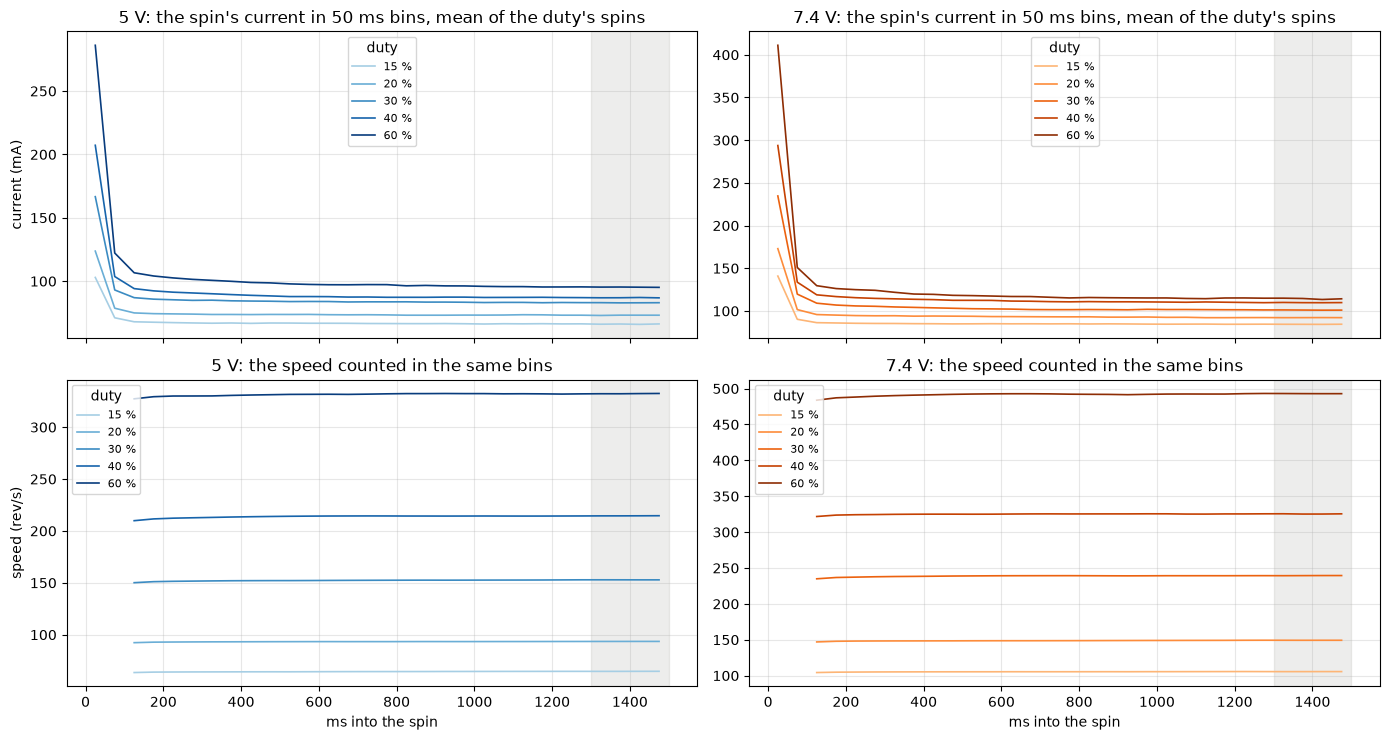

across the 200 ms window the speed moves +0.03 % on average (sd 0.12, -0.22 to +0.38)
and the current -0.13 mA (sd 0.60, -3.66 to +0.66); over the last 500 ms the current falls at -1.1 mA/s on average (-8.4 to +3.2)


In [8]:
BIN_MS = 50
NB = BIN_MS * FS // 1000                                  # rows per bin
rows = []
for _, C in cycles.iterrows():
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    zero_i = tel.baseline(df)["current_raw"].median()
    for d, sp, co in pairs(df):
        x = sp["current_raw"].to_numpy(float)
        f0 = float(CYC[(CYC["k"] == C["k"]) & (CYC["dir"] == d)]["f_spin"].iloc[0])   # the window's own count, the centre of every bin's band
        for b in range(len(x) // NB):
            seg = x[b * NB:(b + 1) * NB]
            wide = x[max(b * NB - NB // 2, 0):(b + 1) * NB + NB // 2]                  # half a bin of margin each side for the filter
            f = count_cycles(wide, f0)[0] if b >= 2 else np.nan                       # from 100 ms on, where the speed is within the band
            rows.append({"k": int(C["k"]), "level": float(C["volts_set"]), "duty": int(C["duty_pct"]), "dir": d, "t_ms": BIN_MS * b + BIN_MS / 2,
                         "i_ma": (seg.mean() - zero_i - I_DRIVE_OFFSET) * A_PER_COUNT * 1e3, "rev_s": f / N_R})
SET = pd.DataFrame(rows)
fig, ax = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
for j, v in enumerate(COLOR):
    for duty, g in SET[SET["level"] == v].groupby("duty"):
        m = g.groupby("t_ms").mean(numeric_only=True)                                # the mean of the duty's six spins, bin by bin
        ax[0, j].plot(m.index, m["i_ma"], "-", lw=1.2, color=SHADE[v][duty], label=f"{duty} %")
        ax[1, j].plot(m.index, m["rev_s"], "-", lw=1.2, color=SHADE[v][duty], label=f"{duty} %")
    ax[0, j].set_title(f"{v:g} V: the spin's current in {BIN_MS} ms bins, mean of the duty's spins"); ax[1, j].set_title(f"{v:g} V: the speed counted in the same bins")
    ax[1, j].set_xlabel("ms into the spin")
    for a in ax[:, j]:
        a.axvspan(SPIN_LEN_MS - SPIN_MS, SPIN_LEN_MS, color=MUTED, alpha=0.15); a.grid(alpha=0.3); a.legend(fontsize=8, title="duty")
ax[0, 0].set_ylabel("current (mA)"); ax[1, 0].set_ylabel("speed (rev/s)")
plt.tight_layout(); plt.show()

# each spin across the window: the last 100 ms against the first 100 ms of the 200 ms window, and the current's slope over the last 500 ms
drift = []
for (k, d), g in SET.groupby(["k", "dir"]):
    win = g[g["t_ms"] > SPIN_LEN_MS - SPIN_MS]
    first, last = win.iloc[:len(win) // 2], win.iloc[len(win) // 2:]
    tail = g[g["t_ms"] > SPIN_LEN_MS - 500]
    drift.append({"k": k, "dir": d, "speed_drift_pct": (last["rev_s"].mean() / first["rev_s"].mean() - 1) * 100,
                  "i_drift_ma": last["i_ma"].mean() - first["i_ma"].mean(),
                  "i_slope_ma_per_s": np.polyfit(tail["t_ms"] / 1e3, tail["i_ma"], 1)[0]})
DRIFT = pd.DataFrame(drift)
CYC = CYC.drop(columns=[c for c in DRIFT.columns if c not in ("k", "dir") and c in CYC]).merge(DRIFT, on=["k", "dir"], how="left")
print(f"across the 200 ms window the speed moves {DRIFT['speed_drift_pct'].mean():+.2f} % on average (sd {DRIFT['speed_drift_pct'].std():.2f}, "
      f"{DRIFT['speed_drift_pct'].min():+.2f} to {DRIFT['speed_drift_pct'].max():+.2f})")
print(f"and the current {DRIFT['i_drift_ma'].mean():+.2f} mA (sd {DRIFT['i_drift_ma'].std():.2f}, {DRIFT['i_drift_ma'].min():+.2f} to {DRIFT['i_drift_ma'].max():+.2f}); "
      f"over the last 500 ms the current falls at {DRIFT['i_slope_ma_per_s'].mean():+.1f} mA/s on average ({DRIFT['i_slope_ma_per_s'].min():+.1f} to {DRIFT['i_slope_ma_per_s'].max():+.1f})")

The current falls from its start-up peak of 100 to 410 mA to within a few milliamps of its final value in the first 150 ms at the low duties, and within about 15 mA at 60 %. The speed is within 2 % of its final value by the first bin it is counted in. After that the two part ways. The speed is flat to the end of the spin. The current keeps sliding down slowly, by up to about 15 mA between 150 ms and the end of the 60 % spins at 7.4 V, and at about 1 mA/s on average over the last 500 ms. A current that falls while the speed holds is a drag torque that falls with time, since the current at a steady speed is what holds the drag. The rotor warming its bearings and the brushes bedding in over the spin are candidates, and this capture does not separate them.

Across the 200 ms window the speed moves +0.03 % on average, with a spread of 0.12 % and no spin beyond 0.4 %. The window is settled in speed for this experiment. The current moves -0.13 mA on average, with a spread of 0.6 mA. One spin stands out, the 60 % spin at 7.4 V in direction +1 of cycle 29, whose current falls 3.7 mA across the window while its speed holds. That spin's current drops out about 420 times a second, the next section's subject, and a dropout rate that changes across the window would move the mean. The no-load-current notebook reads this window for the drag and carries the slide as its margin.

### Rows where the brush path opens

The raw traces showed single rows at the higher duties where the coast's EMF falls to zero and comes back on the next row. Left, the first 10 ms of the coast that shows them most, with each tap's excursion from its rest. Middle and right, how often the spin's current drops out and how many such rows each coast holds, against the speed. The thing to see is what the taps do in those rows, and where and in which direction the rows appear.

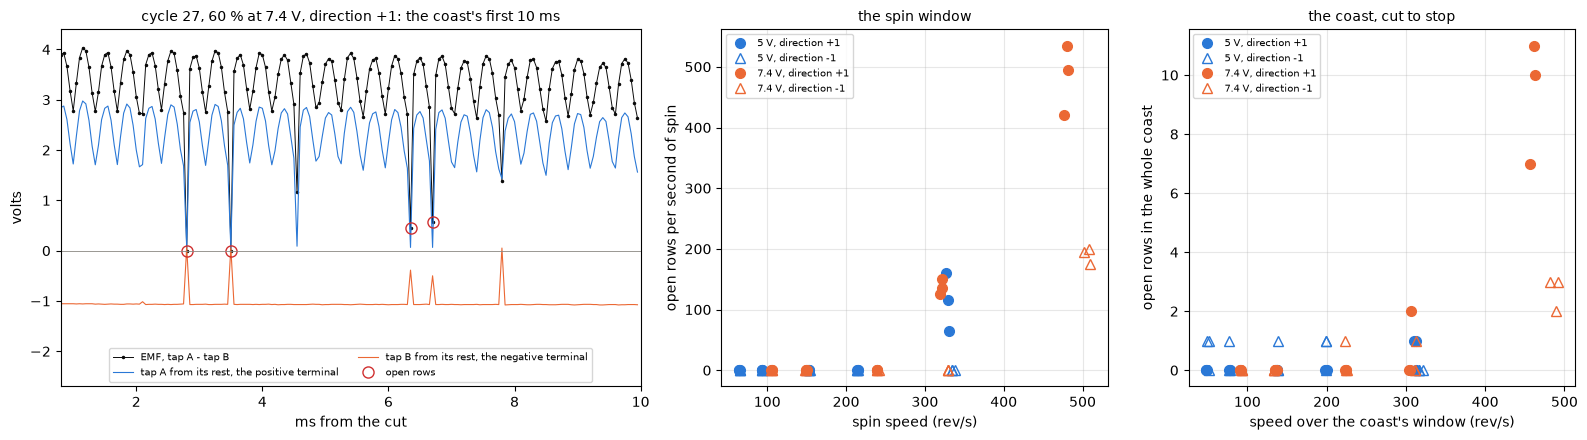

cycle 27 direction +1: 4 open rows in the first 10 ms, both taps at [0.06 0.06 0.06 0.06] and [ 0.06  0.06 -0.39 -0.5 ] V from rest
direction +1: 32 open rows over all 30 coasts, 9 spins with any; the spins at 60 % of 7.4 V open 483 times a second
direction -1: 16 open rows over all 30 coasts, 3 spins with any; the spins at 60 % of 7.4 V open 190 times a second


In [9]:
K_OPEN = int(cycles[(cycles["volts_set"] == 7.4) & (cycles["duty_pct"] == 60)]["k"].iloc[0])   # the first 60 % cycle at 7.4 V
df, meta = tel.load(cycle_folder(K_OPEN), BOARD)
rest = tel.baseline(df)
d, sp, co = pairs(df)[0]                                                  # direction +1
z = cut_row(co)
n = 200                                                                   # the first 10 ms past the cut
e = coast_emf(co, d, z, (rest["vmotor_a"] - rest["vmotor_b"]).median())[:n]
bad = open_rows(e)
ta = (co["vmotor_a"].to_numpy(float)[z:z + n] - rest["vmotor_a"].median()) * V_PER_COUNT   # tap A from its rest, in terminal volts
tb = (co["vmotor_b"].to_numpy(float)[z:z + n] - rest["vmotor_b"].median()) * V_PER_COUNT   # tap B the same
t = np.arange(n) / FS * 1e3
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax[0].plot(t, e, ".-", lw=0.7, ms=3, color=INK, label="EMF, tap A - tap B")
ax[0].plot(t, ta, lw=0.8, color=BLUE, label="tap A from its rest, the positive terminal")
ax[0].plot(t, tb, lw=0.8, color=ORANGE, label="tap B from its rest, the negative terminal")
ax[0].plot(t[bad], e[bad], "o", ms=8, mfc="none", color="#d03030", label="open rows")
ax[0].axhline(0, color=MUTED, lw=0.6)
ax[0].set_xlabel("ms from the cut"); ax[0].set_ylabel("volts"); ax[0].set_xlim(0.8, 10); ax[0].set_ylim(-2.7, 4.4)
ax[0].legend(fontsize=7, loc="lower center", ncol=2)
ax[0].set_title(f"cycle {K_OPEN}, 60 % at 7.4 V, direction +1: the coast's first 10 ms", fontsize=10)
for v in COLOR:
    for d in (1, -1):
        h = CYC[(CYC["level"] == v) & (CYC["dir"] == d)]
        kw = dict(ls="none", ms=7, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
        ax[1].plot(h["spin_speed_rev_s"], h["spin_open_per_s"], MARK[d], **kw)              # rows where the spin's current drops out
        ax[2].plot(h["speed_rev_s"], h["coast_open_rows"], MARK[d], **kw)                    # rows where the coast's EMF collapses
ax[1].set_ylabel("open rows per second of spin"); ax[1].set_xlabel("spin speed (rev/s)"); ax[1].set_title("the spin window", fontsize=10)
ax[2].set_ylabel("open rows in the whole coast"); ax[2].set_xlabel("speed over the coast's window (rev/s)"); ax[2].set_title("the coast, cut to stop", fontsize=10)
for a in ax[1:]:
    a.grid(alpha=0.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"cycle {K_OPEN} direction +1: {int(bad.sum())} open rows in the first 10 ms, both taps at {np.round(ta[bad], 2)} and {np.round(tb[bad], 2)} V from rest")
for d in (1, -1):
    h = CYC[CYC["dir"] == d]
    print(f"direction {d:+d}: {int(h['coast_open_rows'].sum())} open rows over all {len(h)} coasts, {int((h['spin_open_per_s'] > 0).sum())} spins with any; "
          f"the spins at 60 % of 7.4 V open {h[(h['level'] == 7.4) & (h['duty'] == 60)]['spin_open_per_s'].mean():.0f} times a second")

In two of the four open rows of this window, at 2.8 and 3.5 ms, both taps sit 0.06 V from their rest, at the bias node, and the EMF reads zero. In the other two tap A is at its rest and tap B is part way back to it. Two terminals back at the bias node together is what a winding disconnected from the board gives, since with no path for current each terminal settles where its divider puts it. An EMF that really fell to zero would look the same in one row, but that needs the rotor's EMF to go from 3.4 V to zero and back within one 50 us row, while the ordinary commutation dips in the same trace go no lower than about 2.7 V. So these rows are most likely moments when the circuit between the board and the winding is open, and the brushes on the commutator are the likely place, since that is the contact that moves. I hold that with moderate to high confidence. Some events show on one tap only, like the dip of tap A at 4.5 ms with tap B still at its clamp. The two taps are converted one after the other within a row, so an opening shorter than the gap between the two conversions is caught by one tap and not the other, and that row reads a part of the EMF. The 30 % threshold bridges the full openings and the deepest partial ones and leaves the shallower ones as read.

The openings are not spread evenly. In the spins the current drops out only in direction +1 at 60 % on 5.0 V, 65 to 160 times a second, at 40 % on 7.4 V, 125 to 150 times a second, and at 60 % on 7.4 V, 420 to 535 times a second, and in direction -1 only at 60 % on 7.4 V, 175 to 200 times a second. The coasts hold 32 open rows over all thirty coasts in direction +1, 28 of them in the three 60 % coasts at 7.4 V, and 16 in direction -1, half of them single rows scattered through the slow coasts. So the path opens with speed and much more in direction +1, in the spin and in the coast alike. A lead or a connector that opens would not care about the direction the rotor turns, so the direction points at the brushes, with moderate confidence. The two directions run the motor's brushes against the commutator in opposite senses, and a brush that rides one way more lightly than the other is one way a small motor can end up with a favored direction.

In the 60 % coasts at 7.4 V the open rows inside the 10 ms window are 2 to 4 out of about 200, and they read zero where the EMF is 3.3 V. That takes 1 to 2 % off the window's mean. The figures below carry the coast route both ways.

## Results

### Ke per cycle, both routes

Every cycle's $K_e$ by the coast route with the open rows bridged, the same with them as read, and the spin route, against the spin duty, one panel per level, the direction as the marker, with the cycles' mean dotted. The thing to see is whether the coast route sits flat across the duties and the two routes sit on each other.

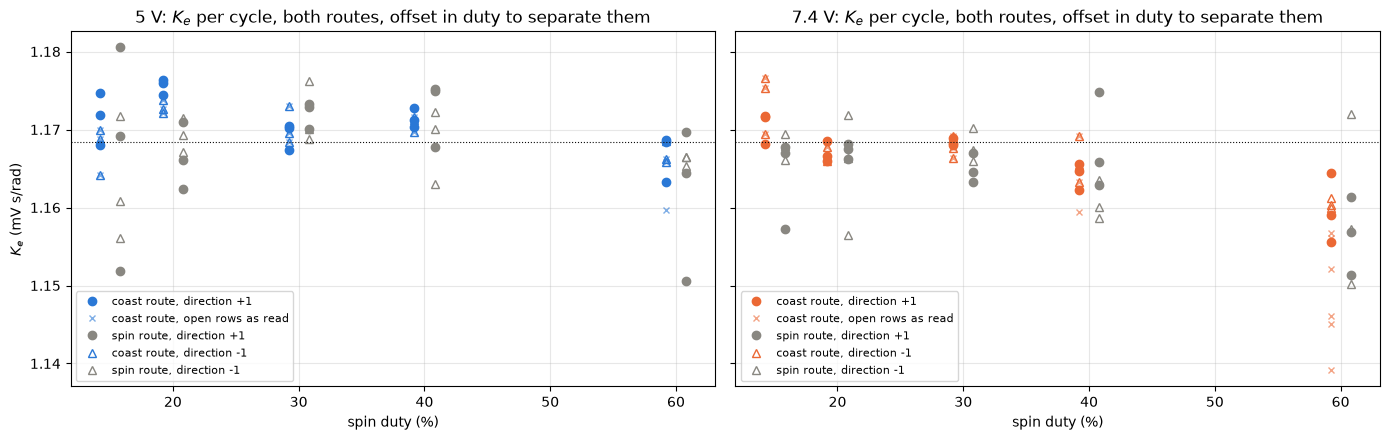

coast route: 1.1684 mV s/rad, sd 0.37 %, se 0.05 %, 1.1556 to 1.1766, n 60
coast route, open rows as read: 1.1671 mV s/rad, sd 0.63 %, se 0.08 %, 1.1391 to 1.1766, n 60
spin route: 1.1660 mV s/rad, sd 0.56 %, se 0.07 %, 1.1502 to 1.1805, n 60
Ke by the coast route 1.1684 mV s/rad, sd 0.37 % over 60 cycles = 7.341 mV per rev/s = 1.2235 mV per ripple Hz
  5 V, direction +1: 1.1709 mV s/rad, sd 0.30 %, +0.22 % from the pooled mean; as read +0.20 %
  5 V, direction -1: 1.1697 mV s/rad, sd 0.24 %, +0.11 % from the pooled mean; as read +0.11 %
  7.4 V, direction +1: 1.1660 mV s/rad, sd 0.38 %, -0.21 % from the pooled mean; as read -0.52 %
  7.4 V, direction -1: 1.1669 mV s/rad, sd 0.41 %, -0.12 % from the pooled mean; as read -0.22 %


In [10]:
ok = CYC[CYC["turned"] & CYC["ke_coast"].notna()]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, v in zip(ax, COLOR):
    g = ok[ok["level"] == v]
    for d in (1, -1):
        h = g[g["dir"] == d]
        a.plot(h["duty"] - 0.8, h["ke_coast"] * 1e3, MARK[d], color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"coast route, direction {d:+d}")
        a.plot(h["duty"] - 0.8, h["ke_read"] * 1e3, "x", ms=5, color=COLOR[v], alpha=0.6, label="coast route, open rows as read" if d == 1 else None)
        a.plot(h["duty"] + 0.8, h["ke_spin"] * 1e3, MARK[d], color=MUTED, mfc=MUTED if d == 1 else "none", label=f"spin route, direction {d:+d}")
    a.axhline(ok["ke_coast"].mean() * 1e3, color=INK, lw=0.8, ls=":")
    a.set_title(f"{v:g} V: $K_e$ per cycle, both routes, offset in duty to separate them"); a.set_xlabel("spin duty (%)"); a.grid(alpha=0.3); a.legend(fontsize=8)
ax[0].set_ylabel("$K_e$ (mV s/rad)")
plt.tight_layout(); plt.show()

for name, c in (("coast route", "ke_coast"), ("coast route, open rows as read", "ke_read"), ("spin route", "ke_spin")):
    x = ok[c].dropna()
    print(f"{name}: {x.mean() * 1e3:.4f} mV s/rad, sd {x.std() / x.mean() * 100:.2f} %, se {x.std() / np.sqrt(len(x)) / x.mean() * 100:.2f} %, "
          f"{x.min() * 1e3:.4f} to {x.max() * 1e3:.4f}, n {len(x)}")
KE_MEAN, KE_SD = ok["ke_coast"].mean(), ok["ke_coast"].std()
print(f"Ke by the coast route {KE_MEAN * 1e3:.4f} mV s/rad, sd {KE_SD / KE_MEAN * 100:.2f} % over {len(ok)} cycles = {KE_MEAN * 2 * np.pi * 1e3:.3f} mV per rev/s "
      f"= {KE_MEAN * 2 * np.pi / N_R * 1e3:.4f} mV per ripple Hz")
for v in COLOR:
    for d in (1, -1):
        g = ok[(ok["level"] == v) & (ok["dir"] == d)]
        print(f"  {v:g} V, direction {d:+d}: {g['ke_coast'].mean() * 1e3:.4f} mV s/rad, sd {g['ke_coast'].std() / g['ke_coast'].mean() * 100:.2f} %, "
              f"{(g['ke_coast'].mean() / KE_MEAN - 1) * 100:+.2f} % from the pooled mean; as read {(g['ke_read'].mean() / KE_MEAN - 1) * 100:+.2f} %")

The coast route reads 1.1684 mV s/rad over the sixty coasts with the open rows bridged, with a spread of 0.37 % and a standard error of 0.05 %, from 1.1556 to 1.1766. As read, with the open rows left in, it reads 1.1671 with a spread of 0.63 %, and the difference is all in the 40 % and 60 % coasts at the top of the speed range, the crosses under the dots there. The spin route reads 1.1660 with a spread of 0.56 %. That is 7.341 mV per revolution per second, or 1.2235 mV per hertz of ripple.

The two directions read the same once the open rows are bridged, 1.16844 and 1.16832 mV s/rad pooled over both levels. The 7.4 V cycles read 0.33 % under the 5.0 V ones. They also run faster, and the windows down the coast below put both levels on one curve against speed, so the level difference is most likely that speed trend and not the rail.

The coast route is flat to about half a percent from 15 to 40 % at both levels. The 60 % coasts at 7.4 V sit about 0.7 % under the mean even with the open rows bridged. That is the top end of the same speed trend, with some shallow openings left in, and the windows down the coast look at it closer.

### The paired difference

The spin route over the coast route, less one, cycle by cycle against the coast's speed. Beside it the difference is split into its two parts, the coast's counted speed over the spin's and $E_0$ over the window's mean EMF. The thing to see is whether the spin route reads high or low on the whole, and which part carries the difference.

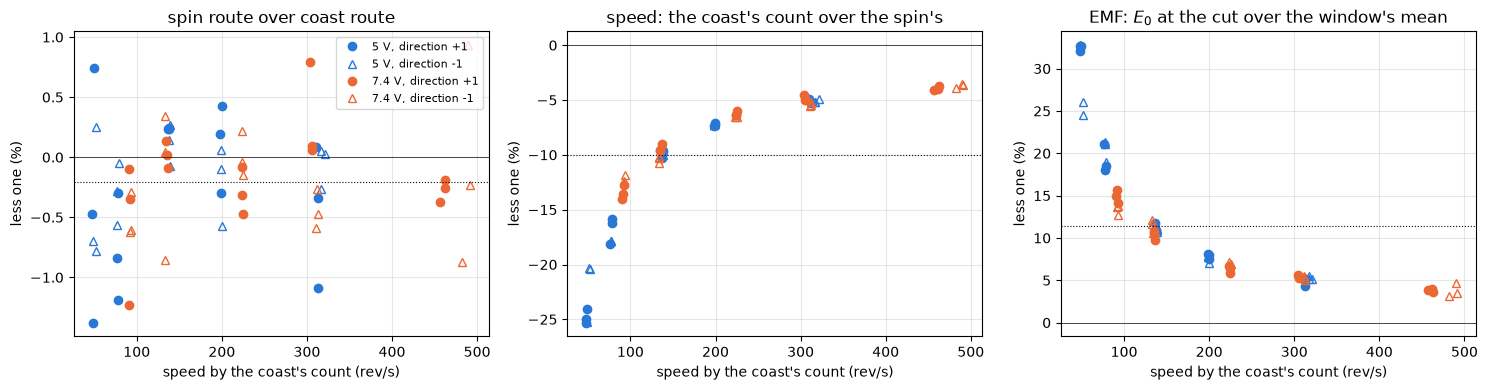

spin / coast - 1: -0.20 % (sd 0.47 %, se 0.06 %, n 60), -1.38 to +0.93 %
  the speed part -10.06 % (-25.3 to -3.5), the EMF part +11.47 % (+3.2 to +32.8)


In [11]:
pair = ok.dropna(subset=["ke_spin"]).copy()
pair["diff_pct"] = (pair["ke_spin"] / pair["ke_coast"] - 1) * 100
pair["speed_part_pct"] = (pair["f_coast"] / pair["f_spin"] - 1) * 100       # the speed in the denominator: the coast's over the spin's
pair["emf_part_pct"] = (pair["e0_v"] / pair["emf_v"] - 1) * 100             # the EMF in the numerator: E0 over the window's mean
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c, title in zip(ax, ["diff_pct", "speed_part_pct", "emf_part_pct"],
                       ["spin route over coast route", "speed: the coast's count over the spin's", "EMF: $E_0$ at the cut over the window's mean"]):
    for v in COLOR:
        for d in (1, -1):
            h = pair[(pair["level"] == v) & (pair["dir"] == d)]
            a.plot(h["speed_rev_s"], h[c], MARK[d], color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
    a.axhline(0, color=INK, lw=0.5); a.axhline(pair[c].mean(), color=INK, lw=0.8, ls=":"); a.set_title(title); a.set_xlabel("speed by the coast's count (rev/s)"); a.grid(alpha=0.3)
    a.set_ylabel("less one (%)")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
DIFF_MEAN, DIFF_SE = pair["diff_pct"].mean(), pair["diff_pct"].std() / np.sqrt(len(pair))
print(f"spin / coast - 1: {DIFF_MEAN:+.2f} % (sd {pair['diff_pct'].std():.2f} %, se {DIFF_SE:.2f} %, n {len(pair)}), "
      f"{pair['diff_pct'].min():+.2f} to {pair['diff_pct'].max():+.2f} %")
print(f"  the speed part {pair['speed_part_pct'].mean():+.2f} % ({pair['speed_part_pct'].min():+.1f} to {pair['speed_part_pct'].max():+.1f}), "
      f"the EMF part {pair['emf_part_pct'].mean():+.2f} % ({pair['emf_part_pct'].min():+.1f} to {pair['emf_part_pct'].max():+.1f})")

The spin route reads 0.20 % under the coast route on average, with a spread of 0.47 % and a standard error of 0.06 %, every cycle between -1.4 and +0.9 %. The two parts are large and nearly cancel. The coast's window sits 3.5 to 25 % below the spin's speed, and $E_0$ sits 3 to 33 % above the window's mean EMF, both largest in the slowest coasts, where 10 ms is a fifth of the whole coast. Their product lands within about a percent of one. So the extrapolation back to the cut and the speed carried across the gap between the streams agree with the coast's own reading to about half a percent on a typical cycle.

The 0.20 % is three standard errors from zero, so it is most likely real, and it is small against either route's spread. The speed part has little room to carry it. The coast's stream opens with a few rows of drive, so the drive ran through the gap and the rotor reached the cut at the spin's speed. The candidate I favor is the extrapolation. A drag that grows with speed makes the decay curve, slowing less as the speed falls. A straight line through the window then sits under the true EMF at the cut, and the spin route reads low. That is a guess with low to moderate confidence until no-load-current fits the drag's shape. The spread of the paired difference is wider at the slow end, under 100 rev/s, where the extrapolation reaches furthest.

### The EMF against the speed

Every turned cycle's window EMF against the speed counted in the same rows, with the line through the origin at the cycles' mean $K_e$, and under it each cycle's $K_e$ from that mean. The thing to see is whether the points lie on one line through the origin from the slowest cycle to the fastest, and whether the two levels and the two directions sit on the same line.

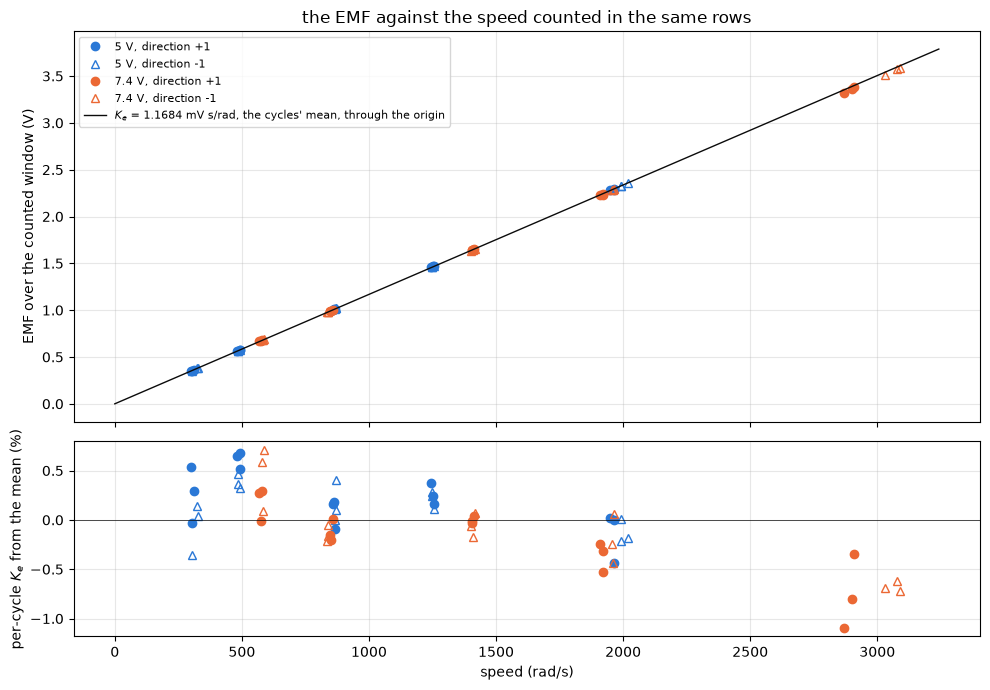

a free line through the cycles: slope 1.1599 mV s/rad, intercept +8.1 mV; the line through the origin: 1.1684 mV s/rad
EMF 0.35 to 3.58 V over 48 to 491 rev/s, ripple 288 to 2948 Hz, 6.8 rows per ripple cycle at the top


In [12]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.linspace(0, ok["w_coast"].max() * 1.05, 10)
for v in COLOR:
    for d in (1, -1):
        h = ok[(ok["level"] == v) & (ok["dir"] == d)]
        kw = dict(ls="none", marker=MARK[d], ms=6, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
        ax[0].plot(h["w_coast"], h["emf_v"], **kw); ax[1].plot(h["w_coast"], (h["ke_coast"] / KE_MEAN - 1) * 100, **kw)
ax[0].plot(x, KE_MEAN * x, "-", color=INK, lw=1, label=f"$K_e$ = {KE_MEAN * 1e3:.4f} mV s/rad, the cycles' mean, through the origin")
ax[0].set_ylabel("EMF over the counted window (V)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3); ax[0].set_title("the EMF against the speed counted in the same rows")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("per-cycle $K_e$ from the mean (%)"); ax[1].set_xlabel("speed (rad/s)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
lin = np.polyfit(ok["w_coast"], ok["emf_v"], 1)
print(f"a free line through the cycles: slope {lin[0] * 1e3:.4f} mV s/rad, intercept {lin[1] * 1e3:+.1f} mV; the line through the origin: {KE_MEAN * 1e3:.4f} mV s/rad")
print(f"EMF {ok['emf_v'].min():.2f} to {ok['emf_v'].max():.2f} V over {ok['speed_rev_s'].min():.0f} to {ok['speed_rev_s'].max():.0f} rev/s, "
      f"ripple {ok['f_coast'].min():.0f} to {ok['f_coast'].max():.0f} Hz, {FS / ok['f_coast'].max():.1f} rows per ripple cycle at the top")

To the eye the points lie on one line through the origin, from 0.35 V at 48 rev/s to 3.58 V at 491 rev/s, both levels and both directions on it. The lower panel shows a tilt that the upper one hides. The cycles under 100 rev/s sit -0.4 to +0.7 % from the mean, mostly over it, and the fastest ones at 7.4 V sit -0.3 to -1.1 % under it. A free line through the cycles gives a slope of 1.1599 mV s/rad and an intercept of +8.1 mV, about two counts of tap difference. Either the EMF over speed falls a little as the speed rises, or an offset of a couple of counts rides on the difference while the rotor turns. Each cycle gives one point at one speed, so the cycles alone do not tell those apart. The windows down the coast read every speed a coast passes through and come closer.

### Ke down the coast

The same window stepped end to end down every coast, so $K_e$ is read at every speed the rotor passes through on its way to a stop, down to 25 rev/s, where three cycles take 20 ms and the window starts to run into the stop. Each window seeds the next one's band with its own frequency. The light points are the windows, the black lines the median of each 25 rev/s bin per direction. The thing to see is whether the read stays flat as the speed falls, whether the coasts from different duties agree where their speeds overlap, and whether the two directions do.

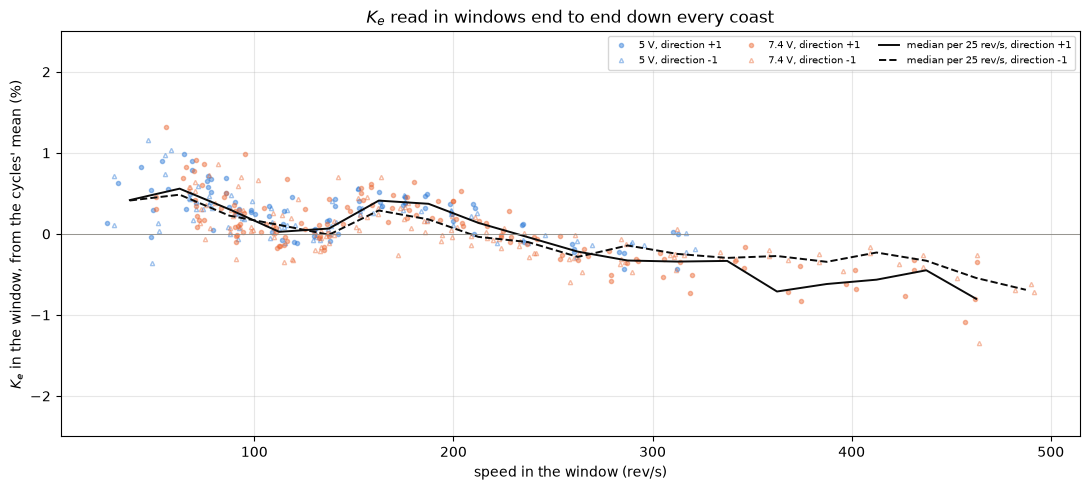

409 windows from 491 down to 26 rev/s, 3 to 29 cycles each
a line through them: -0.26 % per 100 rev/s, +0.43 % at 50 rev/s and -0.60 % at 450 rev/s, windows scatter 0.25 % about it
as a free line of EMF on speed: slope 1.1611 mV s/rad, intercept +7.5 mV
direction -1 less +1 in the median, per bin (%): {37: -0.01, 62: -0.07, 87: -0.08, 112: 0.09, 137: -0.08, 162: -0.12, 187: -0.19, 212: -0.17, 237: -0.06, 262: -0.07, 287: 0.19, 312: 0.09, 337: 0.04, 362: 0.44, 387: 0.27, 412: 0.34, 437: 0.12, 462: 0.26}
a falling Ke, e = K w - b w^2: K 1.1751 mV s/rad, falling 0.26 % per 100 rev/s
  offset   rms 0.43 % over all windows; under 75 rev/s (51 windows) median -0.46 %
  falling  rms 0.25 % over all windows; under 75 rev/s (51 windows) median +0.09 %


In [13]:
FLOOR_REV_S = 25                   # rev/s, under this a window's three cycles take 20 ms and more and run into the stop
rows = []
for _, C in cycles.iterrows():
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    rest = tel.baseline(df)
    zero_e = (rest["vmotor_a"] - rest["vmotor_b"]).median()
    for d, sp, co in pairs(df):
        z = cut_row(co)
        if z is None:
            continue
        e_read = coast_emf(co, d, z, zero_e)
        e = bridge(e_read, open_rows(e_read))
        smooth = np.convolve(e, np.ones(NBH) / NBH, mode="same")
        stop = COAST_FROM + np.flatnonzero(smooth[COAST_FROM:] < TURN_V)[0]   # the row the EMF falls under TURN_V, the rotor about stopped
        start, f = COAST_FROM, line_freq(e[COAST_FROM:COAST_FROM + 200])
        while True:                                                     # windows end to end down the coast, each seeded by the last
            f, i0, i1, n = read_window(e, start, f)
            if not np.isfinite(f) or f / N_R < FLOOR_REV_S or i1 > stop:  # past the floor or the stop, a count of noise
                break
            w = 2 * np.pi * f / N_R
            rows.append({"k": int(C["k"]), "level": float(C["volts_set"]), "duty": int(C["duty_pct"]), "dir": d, "t_ms": (i0 + i1) / 2 / FS * 1e3,
                         "rev_s": f / N_R, "w": w, "emf_v": e[i0:i1].mean(), "emf_read_v": e_read[i0:i1].mean(), "cycles": n})
            start = i1
ALONG = pd.DataFrame(rows)
ALONG["ke"] = ALONG["emf_v"] / ALONG["w"]
ALONG["dev_pct"] = (ALONG["ke"] / KE_MEAN - 1) * 100
ALONG["bin"] = (ALONG["rev_s"] // 25) * 25 + 12.5                       # 25 rev/s bins, named by their middle
fig, ax = plt.subplots(figsize=(11, 5))
for v in COLOR:
    for d in (1, -1):
        h = ALONG[(ALONG["level"] == v) & (ALONG["dir"] == d)]
        ax.plot(h["rev_s"], h["dev_pct"], MARK[d], ms=3, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", alpha=0.45, label=f"{v:g} V, direction {d:+d}")
for d, ls in ((1, "-"), (-1, "--")):
    m = ALONG[ALONG["dir"] == d].groupby("bin")["dev_pct"].median()
    ax.plot(m.index, m.values, ls, color=INK, lw=1.4, label=f"median per 25 rev/s, direction {d:+d}")
ax.axhline(0, color=MUTED, lw=0.6)
ax.set_xlabel("speed in the window (rev/s)"); ax.set_ylabel("$K_e$ in the window, from the cycles' mean (%)"); ax.set_ylim(-2.5, 2.5)
ax.set_title("$K_e$ read in windows end to end down every coast"); ax.legend(fontsize=7, ncol=3); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
trend = np.polyfit(ALONG["rev_s"], ALONG["dev_pct"], 1)                 # a straight line through the windows' deviation against speed
sd_resid = np.std(ALONG["dev_pct"] - np.polyval(trend, ALONG["rev_s"]))
lin_w = np.polyfit(ALONG["w"], ALONG["emf_v"], 1)                       # the same windows as a free line of EMF on speed
print(f"{len(ALONG)} windows from {ALONG['rev_s'].max():.0f} down to {ALONG['rev_s'].min():.0f} rev/s, {ALONG['cycles'].min()} to {ALONG['cycles'].max()} cycles each")
print(f"a line through them: {trend[0] * 100:+.2f} % per 100 rev/s, {np.polyval(trend, 50):+.2f} % at 50 rev/s and {np.polyval(trend, 450):+.2f} % at 450 rev/s, "
      f"windows scatter {sd_resid:.2f} % about it")
print(f"as a free line of EMF on speed: slope {lin_w[0] * 1e3:.4f} mV s/rad, intercept {lin_w[1] * 1e3:+.1f} mV")
med = ALONG.groupby(["bin", "dir"])["dev_pct"].median().unstack("dir")
print("direction -1 less +1 in the median, per bin (%):", {int(b): round(r, 2) for b, r in (med[-1] - med[1]).dropna().items()})
# two ways to describe the tilt, fitted to the same windows: a fixed offset on the EMF, e = K w + c, and a Ke that falls in
# proportion to the speed, e = K w - b w^2, and each one's residual as a share of the window's EMF, overall and at the slow end
X2 = np.c_[ALONG["w"], ALONG["w"] ** 2]
quad = np.linalg.lstsq(X2, ALONG["emf_v"], rcond=None)[0]
res = pd.DataFrame({"rev_s": ALONG["rev_s"],
                    "offset": (ALONG["emf_v"] - np.polyval(lin_w, ALONG["w"])) / ALONG["emf_v"] * 100,
                    "falling": (ALONG["emf_v"] - X2 @ quad) / ALONG["emf_v"] * 100})
slow = res[res["rev_s"] < 75]
print(f"a falling Ke, e = K w - b w^2: K {quad[0] * 1e3:.4f} mV s/rad, falling {-quad[1] / quad[0] * 2 * np.pi * 100 * 100:.2f} % per 100 rev/s")
for m in ("offset", "falling"):
    print(f"  {m:8s} rms {np.sqrt(np.mean(res[m] ** 2)):.2f} % over all windows; under 75 rev/s ({len(slow)} windows) median {slow[m].median():+.2f} %")

The windows from every duty and both levels fall on one band where their speeds overlap, so the shape belongs to the motor or the chain and to no single coast. The read is not flat. It sits about +0.5 % over the cycles' mean at 50 to 75 rev/s and falls to about -0.7 % at 450 to 490 rev/s. A straight line through the windows falls 0.26 % per 100 rev/s, +0.43 % at 50 rev/s and -0.60 % at 450 rev/s, and the windows scatter 0.25 % about it. That is a change of about 1 % over the speed range of this capture, about three times the spread of the per-cycle values, and the per-cycle tilt of the last figure is the same thing seen one point per coast. On top of the line there is a bump of about 0.4 % at 150 to 200 rev/s, where the read climbs and falls again. That speed is where the negative terminal reaches its clamp, the two-taps section below, at about 1.3 V of EMF.

The same windows as a free line of EMF on speed give 1.1611 mV s/rad and +7.5 mV, close to the per-cycle line. That is one way to describe the tilt, a fixed offset of about 8 mV on the EMF. The other is a $K_e$ that falls in proportion to the speed, $e = K \, \omega - b \, \omega^2$, which fits with 1.1751 mV s/rad at standstill falling 0.26 % per 100 rev/s. The two part at the slow end, where an offset grows as $1/\omega$. Over all 409 windows the falling $K_e$ leaves 0.25 % rms and the offset 0.43 %, and on the 51 windows under 75 rev/s the offset reads 0.46 % too high in the median where the falling $K_e$ is within 0.1 %. So inside this zero the data favors a $K_e$ that falls with speed over a fixed offset, with moderate confidence; the next section shows the zero itself is the question. The slowest windows hold only three cycles each, and a shape between the two is not excluded.

The two directions agree within 0.2 % in every bin up to 350 rev/s. Above it direction +1 reads 0.1 to 0.4 % under direction -1, which is where the openings in direction +1 are frequent, and the shallow openings that the 30 % threshold leaves as read are the likely cause.

Where the speed trend comes from is open, and the next section finds that the zero the EMF is read against decides whether there is one. A commutation process that takes a fixed time rather than a fixed angle would take a larger share of each ripple cycle as the speed rises and pull the mean EMF down with it. So would openings too short for either tap to catch, which this motor has at speed, as the section on the open rows shows. A chain that reads the difference a little differently depending on where the two terminals sit would put the bump at the clamp and a tilt above it. None of these is tested here, and the Open questions carry the experiments that would split them.

### The two directions

The spin's speed, the spin's current and the coast route's $K_e$ in direction -1 over direction +1, less one, at each level and duty, the mean of three cycles each way. The thing to see is how big the speed split gets, whether the current and $K_e$ follow it, and where it appears.

### The zero, read again

The EMF above is the tap difference less the rest difference, about -1 count, taken off both directions alike. That is one choice. The rest is a torque-off state, and the coast is not; with the bridge open and the rotor stopped, 0.5 to 0.8 s past the cut, the same difference reads about -1.3 counts after a +1 coast and +1.2 after a -1 coast, a number that follows the direction of the current that just flowed and that the rest difference does not. The count of the ripple's crossings does not care about a constant, so the zero moves the EMF's mean and nothing else, and a constant of a few millivolts is 1 % of the slowest windows and a tenth of that at the fastest. So the same windows are read again under four zeros: none, the rest difference taken off both directions alike as above, the rest difference signed by the direction, and the coast's own tail. The open rows are masked here instead of bridged, left out of the window's mean where they fall under half the window's median, which also takes the shallower openings the 30 % threshold leaves in. Left, $K_e$ in the windows against speed, the median per 25 rev/s under each zero. Right, the per-cycle $K_e$ by direction under each zero. The thing to see is which zero puts the line through the origin and the two directions on each other, and whether the trend survives it.

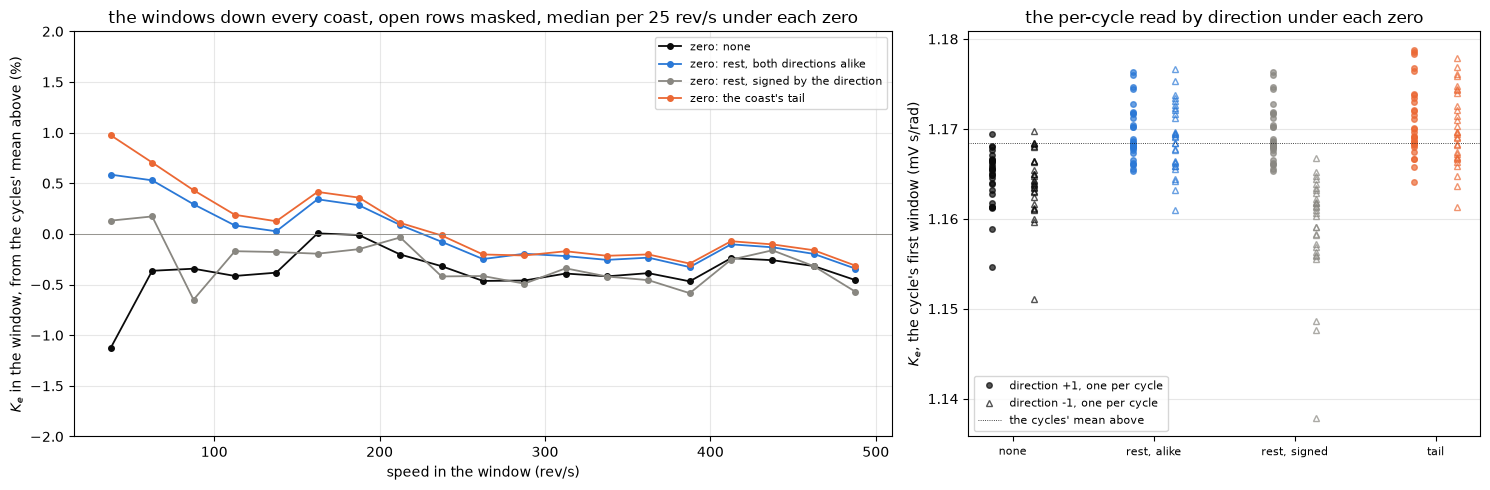

the tap difference at rest -1.03 counts (sd 0.18); in the coast's tail, signed by the direction, direction +1 -1.29 (sd 0.04), direction -1 +1.23 (sd 0.05); 4.03 mV per count
409 windows, 84 rows masked in 43 of them
zero none                          : per cycle 1.1643 mV s/rad, sd 0.29 %, direction +1 over -1 +0.04 %; windows: +0.02 % per 100 rev/s, -0.33 % at 50 and -0.26 % at 450 rev/s; a free line of EMF on speed: slope 1.1643 mV s/rad, intercept +0.7 mV
zero rest, both directions alike   : per cycle 1.1692 mV s/rad, sd 0.29 %, direction +1 over -1 +0.04 %; windows: -0.20 % per 100 rev/s, +0.40 % at 50 and -0.40 % at 450 rev/s; a free line of EMF on speed: slope 1.1643 mV s/rad, intercept +4.9 mV
zero rest, signed by the direction : per cycle 1.1643 mV s/rad, sd 0.60 %, direction +1 over -1 +0.90 %; windows: -0.01 % per 100 rev/s, -0.29 % at 50 and -0.31 % at 450 rev/s; a free line of EMF on speed: slope 1.1639 mV s/rad, intercept +1.0 mV
zero the coast's tail              : per c

In [14]:
MASK_FRAC = 0.5                    # a window row under this share of the window's median is an opening, masked out of the mean
ZEROS = ["none", "rest, both directions alike", "rest, signed by the direction", "the coast's tail"]
Z_COLOR = {ZEROS[0]: INK, ZEROS[1]: BLUE, ZEROS[2]: MUTED, ZEROS[3]: ORANGE}
rows, tails = [], []
for _, C in cycles.iterrows():
    df, meta = tel.load(cycle_folder(C["k"]), BOARD)
    rest = tel.baseline(df)
    zero_e = (rest["vmotor_a"] - rest["vmotor_b"]).median()
    for d, sp, co in pairs(df):
        z = cut_row(co)
        if z is None:
            continue
        raw = ((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:]        # signed by the direction, in counts, no zero
        tail = raw[TAIL_FROM:].mean()                                             # the rotor stopped, the bridge still open
        tails.append({"k": int(C["k"]), "level": float(C["volts_set"]), "dir": d, "rest_counts": zero_e, "tail_counts": tail * d})
        zeros = {ZEROS[0]: 0.0, ZEROS[1]: zero_e, ZEROS[2]: zero_e * d, ZEROS[3]: tail}
        e_ref = (raw - zero_e) * V_PER_COUNT                                      # the read above, which seeds the windows
        e = bridge(e_ref, open_rows(e_ref))
        smooth = np.convolve(e, np.ones(NBH) / NBH, mode="same")
        below = np.flatnonzero(smooth[COAST_FROM:] < TURN_V)
        if not len(below):
            continue
        stop = COAST_FROM + below[0]
        start, f, first = COAST_FROM, line_freq(e[COAST_FROM:COAST_FROM + 200]), True
        while True:
            f, i0, i1, n = read_window(e, start, f)
            if not np.isfinite(f) or f / N_R < FLOOR_REV_S or i1 > stop:
                break
            seg = raw[i0:i1]
            keep = seg >= MASK_FRAC * np.median(seg)                              # the openings, shallow ones included, left out
            row = {"k": int(C["k"]), "level": float(C["volts_set"]), "duty": int(C["duty_pct"]), "dir": d, "first": first,
                   "rev_s": f / N_R, "w": 2 * np.pi * f / N_R, "masked": int((~keep).sum())}
            for name, z0 in zeros.items():
                row[name] = ((seg[keep] - z0) * V_PER_COUNT).mean() / row["w"]      # Ke under this zero, V s/rad
            rows.append(row)
            start, first = i1, False
AZ = pd.DataFrame(rows)
TAILS = pd.DataFrame(tails)
AZ["bin"] = (AZ["rev_s"] // 25) * 25 + 12.5
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
for name in ZEROS:
    m = AZ.groupby("bin")[name].median()
    ax[0].plot(m.index, (m.values / KE_MEAN - 1) * 100, "o-", ms=4, lw=1.3, color=Z_COLOR[name], label=f"zero: {name}")
ax[0].axhline(0, color=MUTED, lw=0.6); ax[0].set_ylim(-2, 2)
ax[0].set_xlabel("speed in the window (rev/s)"); ax[0].set_ylabel("$K_e$ in the window, from the cycles' mean above (%)")
ax[0].set_title("the windows down every coast, open rows masked, median per 25 rev/s under each zero"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
FIRST = AZ[AZ["first"]]
for j, name in enumerate(ZEROS):
    for d, off in ((1, -0.15), (-1, 0.15)):
        g = FIRST[FIRST["dir"] == d]
        ax[1].plot(np.full(len(g), j + off), g[name] * 1e3, MARK[d], ms=4, color=Z_COLOR[name], mfc=Z_COLOR[name] if d == 1 else "none", alpha=0.7,
                   label=f"direction {d:+d}, one per cycle" if j == 0 else None)
ax[1].axhline(KE_MEAN * 1e3, color=INK, lw=0.6, ls=":", label="the cycles' mean above")
ax[1].set_xticks(range(len(ZEROS)), ["none", "rest, alike", "rest, signed", "tail"], fontsize=8); ax[1].set_ylabel("$K_e$, the cycle's first window (mV s/rad)")
ax[1].set_title("the per-cycle read by direction under each zero"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()
print(f"the tap difference at rest {TAILS['rest_counts'].mean():+.2f} counts (sd {TAILS['rest_counts'].std():.2f}); in the coast's tail, signed by the direction, "
      + ", ".join(f"direction {d:+d} {TAILS[TAILS['dir'] == d]['tail_counts'].mean():+.2f} (sd {TAILS[TAILS['dir'] == d]['tail_counts'].std():.2f})" for d in (1, -1))
      + f"; {V_PER_COUNT * 1e3:.2f} mV per count")
print(f"{len(AZ)} windows, {int(AZ['masked'].sum())} rows masked in {int((AZ['masked'] > 0).sum())} of them")
ZSUM = {}
for name in ZEROS:
    fw = FIRST[name]
    tr = np.polyfit(AZ["rev_s"], (AZ[name] / KE_MEAN - 1) * 100, 1)
    ln = np.polyfit(AZ["w"], AZ[name] * AZ["w"], 1)
    by_dir = {d: FIRST[FIRST["dir"] == d][name].mean() for d in (1, -1)}
    ZSUM[name] = {"ke": fw.mean(), "ke_sd": fw.std(), "trend": tr[0] * 100, "intercept_mv": ln[1] * 1e3, "slope": ln[0], "split_pct": (by_dir[1] / by_dir[-1] - 1) * 100}
    print(f"zero {name:30s}: per cycle {fw.mean() * 1e3:.4f} mV s/rad, sd {fw.std() / fw.mean() * 100:.2f} %, direction +1 over -1 {ZSUM[name]['split_pct']:+.2f} %; "
          f"windows: {tr[0] * 100:+.2f} % per 100 rev/s, {np.polyval(tr, 50):+.2f} % at 50 and {np.polyval(tr, 450):+.2f} % at 450 rev/s; "
          f"a free line of EMF on speed: slope {ln[0] * 1e3:.4f} mV s/rad, intercept {ln[1] * 1e3:+.1f} mV")
KE_ZERO_LO = min(v["ke"] - v["ke_sd"] for v in ZSUM.values() if abs(v["split_pct"]) < 0.5)   # the bounds the choice of zero leaves, a zero that splits the directions excluded
KE_ZERO_HI = max(v["ke"] + v["ke_sd"] for v in ZSUM.values() if abs(v["split_pct"]) < 0.5)
topm = FIRST[(FIRST["level"] == 7.4) & (FIRST["duty"] == 60)].groupby("dir")[ZEROS[1]].mean()
print(f"the 60 % cycles at 7.4 V under the rest zero, open rows masked: direction +1 {topm[1] * 1e3:.4f}, -1 {topm[-1] * 1e3:.4f} mV s/rad, "
      f"{(topm[1] / topm[-1] - 1) * 100:+.2f} % apart; bridged above, {(ok[(ok['level'] == 7.4) & (ok['duty'] == 60) & (ok['dir'] == 1)]['ke_coast'].mean() / ok[(ok['level'] == 7.4) & (ok['duty'] == 60) & (ok['dir'] == -1)]['ke_coast'].mean() - 1) * 100:+.2f} %")
print(f"the zeros that keep the directions together span {KE_ZERO_LO * 1e3:.4f} to {KE_ZERO_HI * 1e3:.4f} mV s/rad with the cycles' spread in")

The rest difference reads about -1 count in every cycle, and the coast's tail, where the rotor has stopped and the bridge is still open, reads -1.3 counts after a forward coast and +1.2 after a reverse one, about 5 mV that follows the current that just flowed. A stopped rotor makes no EMF, so that 5 mV is either a voltage the contacts hold for a while after carrying current, which would sit in series with the EMF through the coast, or something the awake open bridge does to the taps. The data does not say which.

The rest difference signed by the direction is out. It splits the two directions by 0.9 %, which no property of the motor does, so it is not an offset present during the coast. The other three keep the directions together to 0.1 %, and they differ by what they add: nothing, 4 mV to both directions, or 5 mV to both. With no zero the free line of EMF on speed passes within a millivolt of the origin and the windows sit flat with speed to about +/-0.3 % from 60 to 490 rev/s; the slowest bin, under 50 rev/s, dips 1 % under no zero and rises 1 % under the other two, so the zero sits somewhere between nothing and the rest difference, and that bin holds too few windows to say where. With the rest difference taken off both directions alike, the read above, the line has a +5 mV intercept here, +8 with the open rows bridged, and the windows tilt by about 0.8 % over the range; the coast's tail gives +6 mV and a tilt of 1 %. A constant of 5 mV and a $K_e$ that falls 1 % over the range are the same shape over this speed range, so the windows cannot tell them apart, and the section above favored the falling $K_e$ only inside the zero it had chosen. A zero of about half the rest difference would leave the windows flat from end to end, and nothing here says that is where it is. The masking lifts the 60 % coasts at 7.4 V from about 0.7 % under the mean to 0.2 to 0.4 % under it, and the two directions there swap order, 0.2 % apart, so the shallow openings owned about half of what the top rung sat under and the rest is the tilt under this zero. The masked read is what the per-zero numbers carry.

So $K_e$ is 1.1643 mV s/rad with no zero and 1.1705 with the tail's, and the result file carries the read above between them with these as its bounds. Whether $K_e$ falls with speed is open until the zero is: the slow end, read at a steady speed, is where 5 mV is 1 to 2 % of the EMF, and the Open questions carry that experiment.

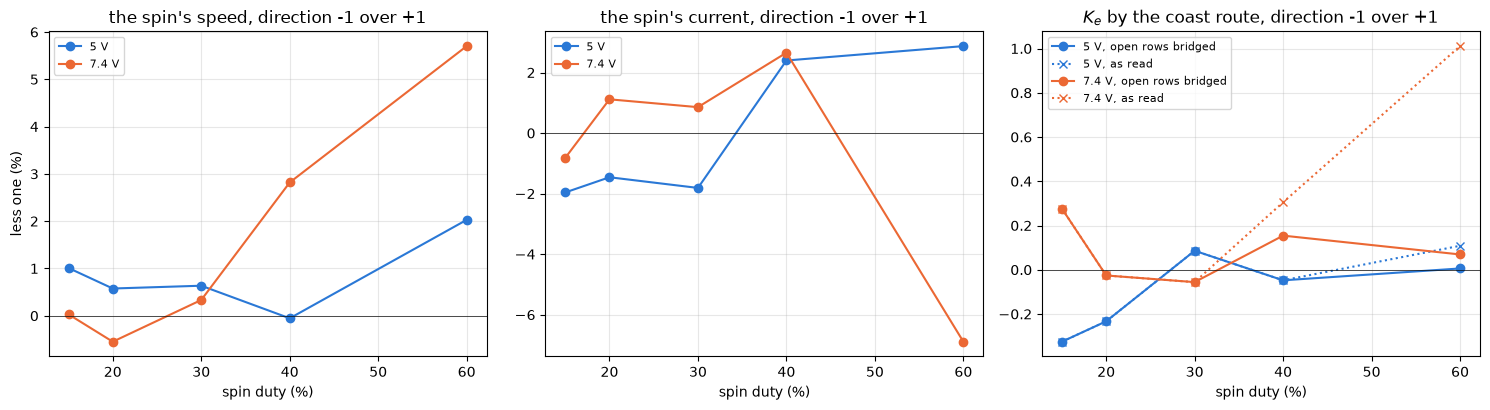

5 V 15 %: speed +1.01 %, current -1.96 %, Ke -0.33 % (as read -0.33 %); the spin's current drops out 0 times a second in direction +1 and 0 in -1
5 V 20 %: speed +0.58 %, current -1.46 %, Ke -0.23 % (as read -0.23 %); the spin's current drops out 0 times a second in direction +1 and 0 in -1
5 V 30 %: speed +0.64 %, current -1.81 %, Ke +0.09 % (as read +0.09 %); the spin's current drops out 0 times a second in direction +1 and 0 in -1
5 V 40 %: speed -0.05 %, current +2.40 %, Ke -0.05 % (as read -0.05 %); the spin's current drops out 0 times a second in direction +1 and 0 in -1
5 V 60 %: speed +2.03 %, current +2.87 %, Ke +0.01 % (as read +0.11 %); the spin's current drops out 113 times a second in direction +1 and 0 in -1
7.4 V 15 %: speed +0.03 %, current -0.82 %, Ke +0.28 % (as read +0.28 %); the spin's current drops out 0 times a second in direction +1 and 0 in -1
7.4 V 20 %: speed -0.55 %, current +1.11 %, Ke -0.03 % (as read -0.03 %); the spin's current drops out 0 times a second 

In [15]:
g = ok.groupby(["level", "duty", "dir"])[["spin_speed_rev_s", "i_spin_a", "ke_coast", "ke_read", "spin_open_per_s"]].mean()
split = (g.xs(-1, level="dir") / g.xs(1, level="dir") - 1) * 100            # direction -1 over +1, less one, at each level and duty
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for v in COLOR:
    s = split.xs(v, level="level")
    ax[0].plot(s.index, s["spin_speed_rev_s"], "o-", color=COLOR[v], label=f"{v:g} V")
    ax[1].plot(s.index, s["i_spin_a"], "o-", color=COLOR[v], label=f"{v:g} V")
    ax[2].plot(s.index, s["ke_coast"], "o-", color=COLOR[v], label=f"{v:g} V, open rows bridged")
    ax[2].plot(s.index, s["ke_read"], "x:", color=COLOR[v], label=f"{v:g} V, as read")
for a, title in zip(ax, ["the spin's speed", "the spin's current", "$K_e$ by the coast route"]):
    a.axhline(0, color=INK, lw=0.5); a.set_title(f"{title}, direction -1 over +1"); a.set_xlabel("spin duty (%)"); a.grid(alpha=0.3); a.legend(fontsize=8)
ax[0].set_ylabel("less one (%)")
plt.tight_layout(); plt.show()
opens = g["spin_open_per_s"].unstack("dir")
for (v, duty), r in split.iterrows():
    print(f"{v:g} V {duty:2d} %: speed {r['spin_speed_rev_s']:+.2f} %, current {r['i_spin_a']:+.2f} %, Ke {r['ke_coast']:+.2f} % (as read {r['ke_read']:+.2f} %); "
          f"the spin's current drops out {opens.loc[(v, duty), 1]:.0f} times a second in direction +1 and {opens.loc[(v, duty), -1]:.0f} in -1")
print("the spread of the three repeats, the spin's speed in one direction:", f"{ok.groupby(['level', 'duty', 'dir'])['spin_speed_rev_s'].agg(lambda x: x.std() / x.mean() * 100).median():.2f} % median")

The speed splits by direction at three conditions only. Direction -1 runs 2.0 % faster at 60 % on 5.0 V, 2.8 % faster at 40 % on 7.4 V and 5.7 % faster at 60 % on 7.4 V. Everywhere else the two directions sit within 1 %, against a spread of 0.33 % between the three repeats of one direction. Those three conditions are exactly the ones where the spin's current drops out in direction +1, and the split is largest where the dropouts are most frequent, 113, 137 and 483 times a second. The current does not follow one pattern. Direction -1 draws 2.4 to 2.9 % more at 40 and 60 % on 5.0 V and at 40 % on 7.4 V, and 6.9 % less at 60 % on 7.4 V, where it drops out too, 190 times a second. $K_e$ by the coast route stays within 0.3 % between the directions at every condition once the open rows are bridged. As read it splits by up to 1.0 % at 60 % on 7.4 V, which is the openings and not the motor's constant.

So the split is in how the motor runs under drive and not in its EMF. The candidates, with what this data says about each.

- The openings cost drive. Each opening interrupts the winding's current, and the torque goes with it until the current builds back through the winding's inductance. A drive that loses part of its time runs slower at the same duty. The split appears only where direction +1 drops out and grows with the rate, and at 40 % on 7.4 V and 60 % on 5.0 V the direction that drops out also draws less current, which lost drive time predicts. At 60 % on 7.4 V direction +1 draws more current than -1, which this alone does not explain, since both directions drop out there. I hold this as the leading candidate with moderate confidence.
- The brushes sit off the magnetic neutral, so one direction commutates early and the other late. That also gives a speed split that grows with speed, and it would show at every duty in some measure. Below 40 % the split is within 1 % and changes sign, so if it is there it is small. Possible, low confidence, and it may come with the openings rather than instead of them.
- The bridge's two legs are not the same. That would give a split of a similar share at every duty, which the data does not show. Unlikely as the main cause.

Swapping the motor's leads at the board's connector and running the 40 and 60 % cycles at 7.4 V again tells the motor from the board. A split and openings that follow the rotor's direction belong to the motor, and ones that follow the board's direction belong to the bridge. The teardown can then look at how each brush meets the commutator.

### The half-rate line

Left, the spectrum of the spin window's current in both directions of the first 60 % cycle at 7.4 V, with the count's line dashed and half of it dotted. Right, the half line over the full line in every spin against the speed, with the spins where a free peak search lands off the count's line circled. The thing to see is where the half line overtakes the full one and whether the count stayed on the full line there.

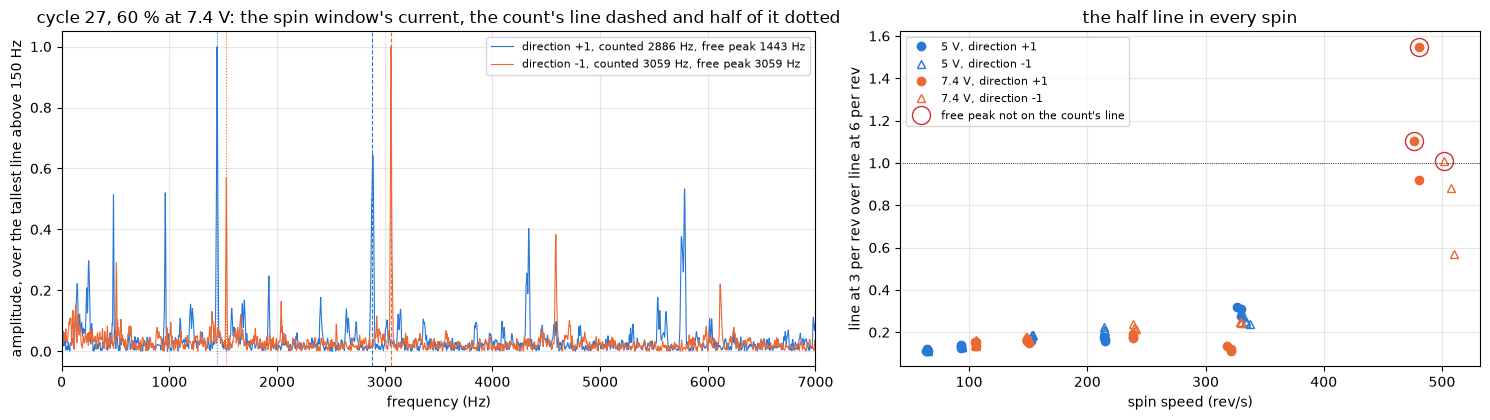

the free peak lands off the count's line in 3 of 60 spins: ['k27 dir +1: 1443 Hz against 2886', 'k29 dir +1: 1429 Hz against 2857', 'k29 dir -1: 1506 Hz against 3012']
the coast's line over the spin's count: 0.842 to 0.968, so the seed sits on the six-per-revolution line in every cycle


In [16]:
K_HALF = int(cycles[(cycles["volts_set"] == 7.4) & (cycles["duty_pct"] == 60)]["k"].iloc[0])
df, meta = tel.load(cycle_folder(K_HALF), BOARD)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
for d, sp, co in pairs(df):
    r = CYC[(CYC["k"] == K_HALF) & (CYC["dir"] == d)].iloc[0]
    f, X = spectrum(sp["current_raw"].to_numpy(float)[-SPIN_MS * FS // 1000:])                # the spin window's current
    ax[0].plot(f, X / X[(f > BAND[0])].max(), lw=0.8, color=BLUE if d == 1 else ORANGE, label=f"direction {d:+d}, counted {r['f_spin']:.0f} Hz, free peak {r['f_free']:.0f} Hz")
    for m, ls in ((0.5, ":"), (1.0, "--")):
        ax[0].axvline(r["f_spin"] * m, color=BLUE if d == 1 else ORANGE, lw=0.8, ls=ls)
ax[0].set_xlim(0, 7000); ax[0].set_xlabel("frequency (Hz)"); ax[0].set_ylabel("amplitude, over the tallest line above 150 Hz")
ax[0].set_title(f"cycle {K_HALF}, 60 % at 7.4 V: the spin window's current, the count's line dashed and half of it dotted"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
for v in COLOR:
    for d in (1, -1):
        h = ok[(ok["level"] == v) & (ok["dir"] == d)]
        ax[1].plot(h["spin_speed_rev_s"], h["spin_half_over_full"], MARK[d], color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
miss = ok[(ok["f_free"] / ok["f_spin"] - 1).abs() > 0.02]
ax[1].plot(miss["spin_speed_rev_s"], miss["spin_half_over_full"], "o", ms=13, mfc="none", color="#d03030", label="free peak not on the count's line")
ax[1].axhline(1, color=INK, lw=0.6, ls=":")
ax[1].set_xlabel("spin speed (rev/s)"); ax[1].set_ylabel("line at 3 per rev over line at 6 per rev"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)
ax[1].set_title("the half line in every spin")
plt.tight_layout(); plt.show()
print(f"the free peak lands off the count's line in {len(miss)} of {len(ok)} spins:",
      [f"k{int(r.k)} dir {int(r.dir):+d}: {r.f_free:.0f} Hz against {r.f_spin:.0f}" for r in miss.itertuples()])
print(f"the coast's line over the spin's count: {(ok['f_seed'] / ok['f_spin']).min():.3f} to {(ok['f_seed'] / ok['f_spin']).max():.3f}, so the seed sits on the six-per-revolution line in every cycle")

At 60 % on 7.4 V the spin's current carries a line at three per revolution that is 0.57 to 1.55 times the height of the six-per-revolution line. In three of the six spins there it is the taller one, and a free peak search reads 1443, 1429 and 1506 Hz against counts of 2886, 2857 and 3012 Hz, half the speed. Everywhere else the half line is 0.11 to 0.32 of the full one, rising slowly with the speed. The count never followed the half line. The coast's early line, which seeds it, sits at 0.84 to 0.97 of the spin's count in every cycle, the coast's first 10 ms running a little slower than the spin, and never near one half. So the seeded count stayed on the six-per-revolution line in every spin, and the reduction table shows the three misses a free search would have made.

Direction +1's spectrum at 60 % on 7.4 V also carries a fuller row of lines at multiples of the revolution rate, about 480 Hz, than direction -1's does. A pattern that repeats once per revolution is what an opening at one place on the commutator would make, and it fits the openings above, with low confidence. The half line itself needs the two halves of each revolution to differ. A difference between the two brushes would make alternate commutation events differ and put a line at three per revolution. That is a candidate, and nothing here tests it.

### The two taps in the coast

A floating winding splits its EMF between the two terminals around the bias node, and the difference reads the whole. Each terminal over the window, in volts from ground, against the window's EMF, with the even split around the bias node drawn in. The thing to see is where each terminal goes, whether either one leaves the converter's range, and whether anything holds a terminal.

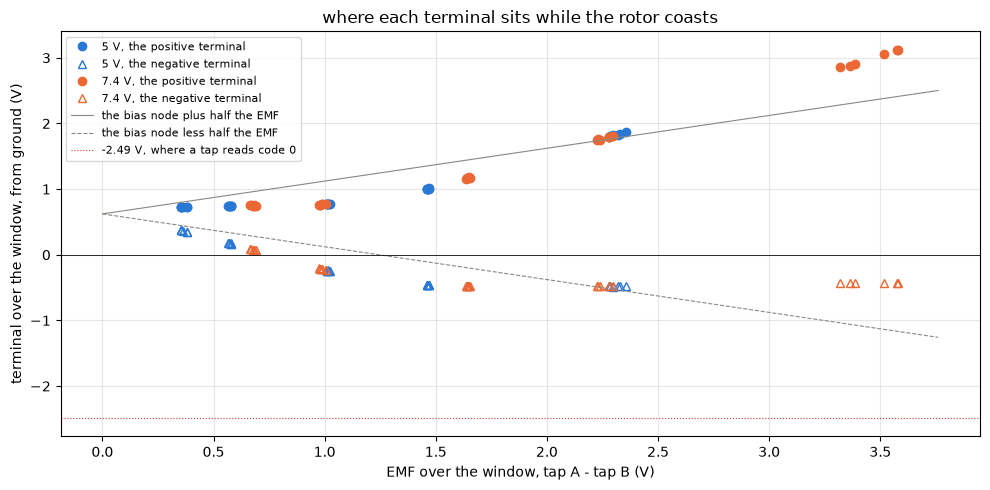

the bias node 0.622 V; the negative terminal reaches -0.484 V at the most (-0.484 to -0.425 V for every EMF over 1.5 V), the positive terminal 0.721 to 3.123 V
under 1.2 V of EMF the positive terminal rises 20 % of the EMF over the bias node and the negative falls 80 %
the current channel over the coast's window reads +0.26 counts over the open bridge's zero (-0.53 to +2.09), +0.05 counts per volt of EMF, so a winding current through the shunt stays under 1.8 mA


In [17]:
rest_tap = tel.baseline(tel.load(cycle_folder(K_SHOW), BOARD)[0])["vmotor_a"].median()     # a tap at rest reads the bias node
VB_V = float(BOARD.term_v(rest_tap, rest_tap))                           # the bias node in volts, where a terminal sits at rest
FLOOR_V = float(BOARD.term_v(0, rest_tap))                               # the terminal at which its tap reads code 0
fig, ax = plt.subplots(figsize=(10, 5))
for v in COLOR:
    g = ok[ok["level"] == v]
    ax.plot(g["emf_v"], g["term_pos_v"], "o", color=COLOR[v], label=f"{v:g} V, the positive terminal")
    ax.plot(g["emf_v"], g["term_neg_v"], "^", color=COLOR[v], mfc="none", label=f"{v:g} V, the negative terminal")
x = np.linspace(0, ok["emf_v"].max() * 1.05, 10)
ax.plot(x, VB_V + x / 2, "-", color=MUTED, lw=0.8, label="the bias node plus half the EMF")
ax.plot(x, VB_V - x / 2, "--", color=MUTED, lw=0.8, label="the bias node less half the EMF")
ax.axhline(0, color=INK, lw=0.6)
ax.axhline(FLOOR_V, color="#d03030", lw=0.8, ls=":", label=f"{FLOOR_V:.2f} V, where a tap reads code 0")
ax.set_xlabel("EMF over the window, tap A - tap B (V)"); ax.set_ylabel("terminal over the window, from ground (V)")
ax.set_title("where each terminal sits while the rotor coasts"); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"the bias node {VB_V:.3f} V; the negative terminal reaches {ok['term_neg_v'].min():+.3f} V at the most "
      f"({ok[ok['emf_v'] > 1.5]['term_neg_v'].min():+.3f} to {ok[ok['emf_v'] > 1.5]['term_neg_v'].max():+.3f} V for every EMF over 1.5 V), "
      f"the positive terminal {ok['term_pos_v'].min():.3f} to {ok['term_pos_v'].max():.3f} V")
low = ok[ok["emf_v"] < 1.2]
print(f"under 1.2 V of EMF the positive terminal rises {((low['term_pos_v'] - VB_V) / low['emf_v']).mean() * 100:.0f} % of the EMF over the bias node and the negative "
      f"falls {((VB_V - low['term_neg_v']) / low['emf_v']).mean() * 100:.0f} %")
ci = np.polyfit(ok["emf_v"], ok["coast_i_counts"], 1)                   # the current channel in the window against the EMF
print(f"the current channel over the coast's window reads {ok['coast_i_counts'].mean():+.2f} counts over the open bridge's zero ({ok['coast_i_counts'].min():+.2f} to "
      f"{ok['coast_i_counts'].max():+.2f}), {ci[0]:+.2f} counts per volt of EMF, so a winding current through the shunt stays under "
      f"{(ok['coast_i_counts'].abs().max()) * A_PER_COUNT * 1e3:.1f} mA")

The split is not even. Under 1.2 V of EMF the positive terminal rises only 20 % of the EMF over the bias node and stays at 0.72 to 0.77 V from ground, while the negative terminal falls 80 % of it. Something holds the positive terminal near 0.75 V. I do not know what it is. At about 1.3 V of EMF the negative terminal reaches -0.43 to -0.48 V and stops there for every EMF beyond, and from there the positive terminal carries the rest, up to 3.12 V at the fastest coast. A terminal stopping half a volt below ground is what the body diode of the bridge's low-side switch on that terminal does, with high confidence.

None of this moves the difference out of range. The lowest terminal is -0.48 V, and a tap reads code 0 only at -2.49 V, so both taps stay well inside the converter at every EMF here. The difference depends on the two terminals only, wherever the pair sits.

Whether the hold on the positive terminal and the clamp on the negative one let a current through the winding is the other question. A current in the winding drops $R \, i$ across it and the terminals read less than the EMF. The current channel over the coast's window reads 0.26 counts over the open bridge's zero on average, about 0.2 mA, with no trend against the EMF, and no cycle reads more than 2.1 counts, 1.8 mA. That bounds a current that returns through the shunt, and at a winding resistance of a few ohms, which rest-resistance measures, 1.8 mA is about 10 mV, a third of a percent of a 3 V EMF. A path that does not cross the shunt is not bounded by this capture. The bump in $K_e$ at 150 to 200 rev/s sits where the negative terminal reaches its clamp, and the read falls away above it. A current that starts at the clamp would pull the read down above it, so it fits the fall and not the rise. That is a candidate with low confidence.

### The current zero under an open bridge

The current channel 0.5 to 0.8 s past the cut, with the rotor stopped and the bridge still open, over the cycle's torque-off zero, every coast. The current-scale result's in-drive offset is the band. The thing to see is whether the open bridge's zero sits where the spin's current assumes it does.

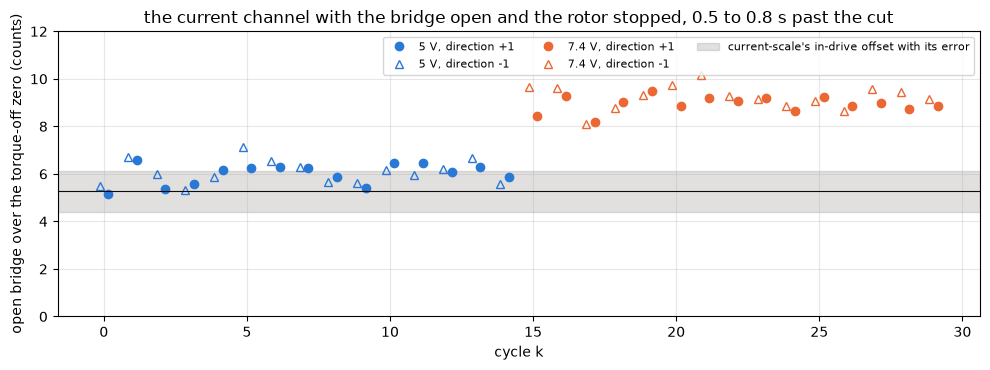

5 V: 6.04 counts over the torque-off zero (sd 0.47, 5.2 to 7.1), the EMF there 1.5 mV at the most; the spin's current with this zero in place of the offset reads -0.69 mA, -0.9 %
7.4 V: 9.09 counts over the torque-off zero (sd 0.45, 8.1 to 10.1), the EMF there 3.4 mV at the most; the spin's current with this zero in place of the offset reads -3.37 mA, -3.4 %


In [18]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for v in COLOR:
    for d in (1, -1):
        h = CYC[(CYC["level"] == v) & (CYC["dir"] == d)]
        ax.plot(h["k"] + (0.15 if d == 1 else -0.15), h["open_zero_counts"], MARK[d], color=COLOR[v], mfc=COLOR[v] if d == 1 else "none", label=f"{v:g} V, direction {d:+d}")
ax.axhspan(CS["drive_offset_counts"]["lo"], CS["drive_offset_counts"]["hi"], color=MUTED, alpha=0.25, label="current-scale's in-drive offset with its error")
ax.axhline(I_DRIVE_OFFSET, color=INK, lw=0.8)
ax.set_xlabel("cycle k"); ax.set_ylabel("open bridge over the torque-off zero (counts)"); ax.set_ylim(0, 12); ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=3)
ax.set_title("the current channel with the bridge open and the rotor stopped, 0.5 to 0.8 s past the cut")
plt.tight_layout(); plt.show()
for v in COLOR:
    g = CYC[CYC["level"] == v]
    print(f"{v:g} V: {g['open_zero_counts'].mean():.2f} counts over the torque-off zero (sd {g['open_zero_counts'].std():.2f}, {g['open_zero_counts'].min():.1f} to "
          f"{g['open_zero_counts'].max():.1f}), the EMF there {g['tail_emf_v'].abs().max() * 1e3:.1f} mV at the most; the spin's current with this zero in place of "
          f"the offset reads {((g['i_spin_open_zero_a'] - g['i_spin_a']) * 1e3).mean():+.2f} mA, {((g['i_spin_open_zero_a'] / g['i_spin_a'] - 1) * 100).mean():+.1f} %")

With the bridge open and the rotor stopped, the current channel reads 6.04 counts over the torque-off zero at 5.0 V, with a spread of 0.47 counts, and 9.09 counts at 7.4 V, with a spread of 0.45. The EMF there is within 3.4 mV of zero, so the winding carries nothing. The current-scale result gives +5.3 +/- 0.9 counts for the offset under drive, from DC laps at 3.7 to 8.0 V, and fitted one offset over every rail. The 5.0 V level agrees with it. The 7.4 V level sits 3.8 counts over it, about four of its standard errors, and every one of the thirty coasts at that level sits over the band.

This is a discrepancy with the stage 1 result, and it matters for the spin's current. With the open bridge's zero in place of the in-drive offset, the spin's current reads 0.7 mA lower at 5.0 V, 0.9 %, and 3.4 mA lower at 7.4 V, 3.4 %. Current-scale's own reading of its offset is the driver's supply current returning through the shunt. A driver whose supply current with its outputs open rises with the rail, where with its outputs held at 100 % it does not, would give this. So would an offset that comes with the open state and differs from the driven one at every rail. The DC laps there drove at 100 % and never left the bridge open, and the spins here switch at 15 to 60 %, so neither zero is known to be the right one for a switching drive. The result file carries the spin's current both ways, `i_spin_a` through current-scale's offset and `i_spin_open_zero_a` through the open bridge's own zero, and no-load-current has to pick with the experiment in the Open questions.

### The results file

$K_e$ by the coast route with the open rows bridged, over every cycle, with the cycles' spread as the bounds, in volt seconds per radian, in millivolts per revolution per second and per ripple hertz. Beside it the same as read, the per-level and per-direction values, the as-read split at 60 % on 7.4 V, the trend down the coast and the windows' scatter about it, the paired difference of the spin route with its standard error, the EMF line's slope and intercept, the speed and EMF ranges, the stop times, the settle figures, the direction split at the top, the open bridge's zero per level, and the per-cycle table for the no-load-current experiment, one row per spin and coast pair.

In [19]:
q = results.quantity

def native(v):
    # JSON takes Python scalars only, and a NaN becomes null
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    if isinstance(v, (np.integer, int)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else float(v)
    return v

def spread(x, unit, scale=1.0):
    # mean with the sd as the bounds
    x = x.dropna() * scale
    return q(x.mean(), x.mean() - x.std(), x.mean() + x.std(), unit)

CYCLE_COLS = {"k": "k", "level": "level", "duty": "duty", "dir": "direction", "turned": "turned", "speed_rev_s": "speed_rev_s", "emf_v": "emf_v",
              "i_spin_a": "i_spin_a", "ke_coast": "ke", "ke_read": "ke_read", "ke_spin": "ke_spin", "e0_v": "e0_v", "dedt_v_per_s": "dedt_v_per_s",
              "f_coast": "f_coast_hz", "coast_cycles": "coast_cycles", "window_ms": "window_ms", "stop_ms": "stop_ms", "spin_speed_rev_s": "spin_speed_rev_s",
              "i_spin_open_zero_a": "i_spin_open_zero_a", "open_zero_counts": "open_zero_counts", "spin_open_per_s": "spin_open_per_s",
              "coast_open_rows": "coast_open_rows", "speed_drift_pct": "speed_drift_pct", "i_drift_ma": "i_drift_ma", "rail_v": "rail_v",
              "duty_applied": "duty_applied_pct"}
cycle_list = [{name: native(r.get(c, np.nan)) for c, name in CYCLE_COLS.items()} for r in CYC.to_dict("records")]
top = ok[(ok["level"] == 7.4) & (ok["duty"] == 60)]
path = results.write("2-motor", "bemf-coast", CAPTURE, pair=MOTOR.key,
              notes="cycles of a 1.5 s spin and a 0.8 s coast with the bridge open, both directions, 15 to 60 % at 5.0 and 7.4 V; ke_v_s_per_rad is the coast "
                    "route, the EMF over the whole ripple cycles closest to 10 ms (at least 3) from 1 ms past the cut over the speed counted in the same rows, "
                    "6 ripple events per revolution, with the rows where the brush path opens bridged, mean over the cycles; its bounds are the span the choice of "
                    "the tap difference's zero leaves (none, the rest difference, the coast's own tail), each with the cycles' sd, since the zero is open; ke_by_zero carries "
                    "each read with the open rows masked, with its trend down the coast, its EMF line's intercept and its direction split beside it; "
                    "ke_clock_class_pct is the class of the board's tick, which paces every count and is not measured here, an accuracy term on Ke and on every speed; "
                    "ke_read_v_s_per_rad leaves those rows as read; the windows down the coast give ke_speed_trend_pct_per_100_rev_s under the rest zero; the spin route is E0 at "
                    "the cut over the spin's current-ripple speed and is reported as its paired difference; terminal volts through the stage 1 terminal-chain "
                    "scale with each cycle's rest difference as the zero, current through current-scale with its in-drive offset taken out (i_spin_a) and, "
                    "beside it, with the open bridge's own zero (i_spin_open_zero_a); cycles is the per-cycle table no-load-current reads",
              ke_v_s_per_rad=q(KE_MEAN, KE_ZERO_LO, KE_ZERO_HI, "V s/rad"),
              ke_mv_per_rev_s=q(KE_MEAN * 2 * np.pi * 1e3, KE_ZERO_LO * 2 * np.pi * 1e3, KE_ZERO_HI * 2 * np.pi * 1e3, "mV per rev/s"),
              ke_by_zero={name: q(v["ke"], v["ke"] - v["ke_sd"], v["ke"] + v["ke_sd"], "V s/rad") for name, v in ZSUM.items()},
              ke_speed_trend_by_zero_pct_per_100_rev_s={name: q(v["trend"], unit="% per 100 rev/s") for name, v in ZSUM.items()},
              emf_line_intercept_by_zero_mv={name: q(v["intercept_mv"], unit="mV") for name, v in ZSUM.items()},
              ke_direction_split_by_zero_pct={name: q(v["split_pct"], unit="%") for name, v in ZSUM.items()},
              tail_zero_counts_by_direction={f"{d:+d}": spread(TAILS[TAILS["dir"] == d]["tail_counts"], "counts") for d in (1, -1)},
              rest_zero_counts=spread(TAILS["rest_counts"], "counts"),
              ke_clock_class_pct=q(1.0, unit="%"),
              ke_mv_per_ripple_hz=q(KE_MEAN * 2 * np.pi / N_R * 1e3, unit="mV/Hz"),
              ke_sd_pct=q(KE_SD / KE_MEAN * 100, unit="%"),
              ke_se_pct=q(KE_SD / np.sqrt(len(ok)) / KE_MEAN * 100, unit="%"),
              ke_read_v_s_per_rad=spread(ok["ke_read"], "V s/rad"),
              ke_by_level={f"{v:g} V": spread(ok[ok["level"] == v]["ke_coast"], "V s/rad") for v in COLOR},
              ke_by_direction={f"{d:+d}": spread(ok[ok["dir"] == d]["ke_coast"], "V s/rad") for d in (1, -1)},
              ke_read_by_direction_top={f"{d:+d}": spread(top[top["dir"] == d]["ke_read"], "V s/rad") for d in (1, -1)},
              ke_speed_trend_pct_per_100_rev_s=q(trend[0] * 100, unit="% per 100 rev/s"),
              ke_window_scatter_pct=q(sd_resid, unit="%"),
              ke_spin_route_pct_diff=q(DIFF_MEAN, DIFF_MEAN - DIFF_SE, DIFF_MEAN + DIFF_SE, "%"),
              emf_line_intercept_mv=q(lin[1] * 1e3, unit="mV"),
              emf_line_slope_v_s_per_rad=q(lin[0], unit="V s/rad"),
              speed_range_rev_s=q(ok["speed_rev_s"].max(), lo=ok["speed_rev_s"].min(), hi=ok["speed_rev_s"].max(), unit="rev/s"),
              emf_range_v=q(ok["emf_v"].max(), lo=ok["emf_v"].min(), hi=ok["emf_v"].max(), unit="V"),
              ripple_per_rev=q(N_R, unit="events/rev"),
              cycles_turned=q(len(ok), unit="count"),
              cycles_total=q(len(CYC), unit="count"),
              stop_ms=q(CYC["stop_ms"].median(), CYC["stop_ms"].min(), CYC["stop_ms"].max(), "ms"),
              spin_speed_drift_pct=q(DRIFT["speed_drift_pct"].mean(), DRIFT["speed_drift_pct"].min(), DRIFT["speed_drift_pct"].max(), "%"),
              spin_current_drift_ma=q(DRIFT["i_drift_ma"].mean(), DRIFT["i_drift_ma"].min(), DRIFT["i_drift_ma"].max(), "mA"),
              direction_speed_split_top_pct=q(split.loc[(7.4, 60), "spin_speed_rev_s"], unit="%"),
              direction_current_split_top_pct=q(split.loc[(7.4, 60), "i_spin_a"], unit="%"),
              open_zero_counts_by_level={f"{v:g} V": spread(CYC[CYC["level"] == v]["open_zero_counts"], "counts") for v in COLOR},
              term_neg_min_v=q(ok["term_neg_v"].min(), unit="V"),
              cycles=cycle_list)
print("wrote", path, "with", len(cycle_list), "cycle rows")

wrote stages/2-motor/bemf-coast/results/mg90-b.json with 60 cycle rows


## Limitations

- The speed has no outside ruler. The count rests on the ripple being six events per revolution, a parts count, 3 slots times 2 brushes, and on the band-pass staying on that line. A camera on the horn grades the ripple count in stage 3, through the gear train, and nothing here does on the bare shaft.
- The clock has no outside ruler either, and it is the largest accuracy term. Every frequency here is a count of rows, and the rows are paced by the board's tick, which the chip derives from its internal RC oscillator, a class of about 1 %. Nothing in this capture measures it. A 1 % error in the tick moves every speed, every deceleration and $K_e$ by 1 %, all the same way, and leaves every shape alone. Counting the stream's rows against the host's clock over a long capture, or a check of the tick against a crystal, reads it.
- The terminal scale is the stage 1 result through the meter, 0.1 % at best. The zero is open. The main read takes each cycle's rest difference off both directions alike, and the coast's own tail says 5 mV with the direction's sign; between no zero and either of those $K_e$ moves 0.6 %, and the result's bounds carry that span. The terminal-chain result also carries an offset of about 2.4 counts read under DC current, which a coast does not have and this notebook does not apply. At the slowest window's 0.35 V one count of difference is 1.1 %, so a fixed offset of a count moves the slow end of the speed trend by about that much and the fast end by a tenth of it, which is why the trend and the zero are one question.
- The open rows are found by a threshold. Rows under 30 % of their neighborhood are bridged, and shallower partial openings stay in the reading. At the top of the speed range in direction +1 those are the most likely reason the read sits 0.1 to 0.4 % under direction -1's. The bridge assumes the winding's EMF ran on through the opening as the line between its neighbors, which is what an open contact predicts and nothing here checks.
- The current in the spin window is the crest sample under PWM at 15 to 60 % duty, and the current-scale grade is DC at 100 %. The zero is a further question, since the open bridge reads 3.8 counts over the graded offset at 7.4 V. The spin's current is carried both ways for the no-load-current experiment to weigh.
- The motor's temperature is not read. The cycles are short and rest at least twenty seconds, so the copper stays near the can, but the magnets' flux moves with temperature too and a warm motor would read a lower $K_e$. Nothing here covers that.
- What holds the positive terminal near 0.75 V in a slow coast is not identified, and a winding current through a path that does not cross the shunt is not bounded.
- The DPS is the supply, trimmed to the level by the board's own rail. The rail sags under the spin by the current times the leads' and the diode's drop, which the rail column records and nothing here needs.
- The coasts are short, 45 to 281 ms. $K_e$ under 48 rev/s is read only on the way down to a stop, in windows of three cycles, never at a steady speed.
- One motor. A second motor of the same batch is read with the meter in rest-resistance for the resistance alone, and nothing says how far $K_e$ moves between cans.

## What earlier work established

Before this stage the same route was tried on a motor of this family out of its servo with a 300 ms spin, aimed at understanding the method rather than at grading a motor. Its data is not reused here, but its conclusions set this capture up.

- The coast route read $K_e$ with a spread of a few tenths of a percent over a dozen cycles and sat flat across 20 to 40 % duty on a 5 V rail, and the spin route agreed with it paired cycle by cycle to within a percent with a wider spread. The coast route was the one to keep, since it needs no current and no resistance. This capture agrees on all three counts over 20 to 40 %, and adds the slope at the ends of a wider speed range.
- A 300 ms spin was still accelerating in its window. At 40 % the current fell a few milliamps across the last 100 ms while the speed climbed a percent, the tails fitted time constants of 70 to 170 ms, and the no-load currents read a few milliamps high for it. The spin here is 1.5 s for that reason. It is settled in speed, and its current still slides slowly, which the earlier run was too short to see.
- A coast with the bridge open reads the EMF, and a brake segment with the low side shorted reads about 4 % of it, a resistive residue and not the EMF. The first floating samples after the cut read low while the taps settle, so the EMF is read over whole ripple periods past the first millisecond and not from the first sample.
- Under drive the current ripple can carry a stronger line at three events per revolution than at six above about half duty, and a free peak search then halves the speed. Here the half line overtakes the full one only at 60 % on 7.4 V, near 480 rev/s, and stays at a third of it at 60 % on 5.0 V, near 330 rev/s, so it follows the speed more than the duty.
- A single terminal reads about half the EMF, the two taps splitting it around the bias node, so the difference is the EMF and one tap on its own is not. Here the split is half and half only in passing. A slow coast puts most of the EMF on the negative terminal, and a fast one clamps the negative terminal and puts the rest on the positive one, which makes a single tap an even poorer reading of the EMF than the earlier note says.
- An in-servo value of the same constant from a drive fit, with the gear train on and the resistance pinned, sat several percent from the bare coast's, and nothing separated the board, the route and the gear train. Stage 3 repeats this experiment in situ and is graded against this notebook for that reason.

## Open questions

- Whether $K_e$ falls with speed at all. Under the rest zero it falls about 1 % from 50 to 490 rev/s, with a bump of 0.4 % at 150 to 200 rev/s; with no zero it is flat to +/-0.3 % from 60 rev/s up and the EMF line passes through the origin, and the two are the same shape over this range. Steady spins at 8 to 12 % on a 5.0 V rail, counted over many cycles at a fixed speed, read the slow end where 5 mV is 1 to 2 % of the EMF, and a coast whose tail is stepped between the open bridge and torque-off with the rotor stopped, a second or two in each state, says which state carries the 5 mV. Those two settle the zero and with it the trend. If a trend survives them, three candidates. A commutation process that takes a fixed time rather than a fixed angle would take a larger share of each ripple cycle as the speed rises, a motor cause. Openings of the brush path too short for either tap to catch would do the same, also the motor. A chain that reads the difference a little differently with where the two terminals sit, or a small current through the clamp that starts near 1.3 V of EMF, would be the board, and the bump sits at that clamp. A scope with a differential probe across the motor's terminals through the 60 % coasts at 7.4 V, read over the same ripple cycles as the board's window, tells them apart. A board cause shows as a difference between the scope's mean and the board's, and a motor cause does not. At a megahertz the same record shows whether the commutation dip has a fixed width in time or in angle, and every opening, however short. Steady spins at 10 and 12 % on a 5.0 V rail, counted over many cycles at a fixed speed, read the slow end of the trend without a decay under it, and split the falling $K_e$ from a fixed offset further.
- Why direction -1 runs up to 5.7 % faster under drive at 60 % on 7.4 V, and why the current splits one way at 40 % and the other at 60 %. The openings costing drive, a brush position off the magnetic neutral and an unequal pair of bridge legs are the candidates, with the openings leading. Swapping the motor's leads at the board's connector and running the 40 and 60 % cycles at 7.4 V again sorts the motor from the board, since a motor cause follows the rotor's direction and a board cause follows the board's. A scope on the current through a 60 % spin in each direction shows how long the current takes to come back after an opening, which is how much drive each one costs, and the teardown shows how each brush meets the commutator.
- Where the current channel's zero sits for a switching drive. The open bridge reads 6.0 counts over the torque-off zero at 5.0 V and 9.1 at 7.4 V, against current-scale's +5.3 +/- 0.9 from DC laps fitted with one offset over every rail. Current-scale's series pass did step by about 4 counts between 4.5 and 5.0 V, and whether that is the same thing is part of this question. A driver supply current that rises with the rail only with its outputs open, or an open state that simply reads differently from a driven one, are the candidates. The DMM on its milliamp range in series with one motor lead through a 40 % spin at 7.4 V reads the true mean current, since the winding's time constant, which the inductance notebook measures, is most likely long against the 50 us PWM period, and the chip's mean with each zero against it says which zero is right. The open bridge's zero read at every rail level from 3.7 to 8.0 V with no motor, beside current-scale's DC laps at the same levels, says whether it follows the rail.
- Why the spin's current keeps falling while its speed holds, by up to 15 mA over a 60 % spin at 7.4 V. Bearings and lubricant warming over the spin and brushes bedding in are the candidates. The same cycle run twice, 20 s apart and then after a long rest, with the thermocouple on the can, splits them, since a warming effect starts lower on the second run and a bedding effect carries over between runs and does not reset with a rest.
- Why the spin route reads 0.20 % under the coast route, three standard errors from zero. The drive ran through the gap between the streams, so the speed at the cut is most likely the spin's. A drag that grows with speed makes the decay curve, slowing less as the speed falls, and a straight line through the window then sits under the true EMF at the cut. No-load-current fits the shape of the decay, and extrapolating with that shape in place of the line should close the difference if this is the cause.
- What holds the positive terminal near 0.75 V in a slow coast. Something in the driver's open output stage is the candidate. A coast with the driver asleep instead of awake with its outputs open, which the sweep tool does not do today, shows whether the hold belongs to the awake driver.
- Whether $K_e$ moves with the motor's temperature. The same cycles run right after a 30 s spin, with the thermocouple on the can, read the constant warm against cold, and the magnets' coefficient would show as a lower EMF at the same counted speed.
- What the tick runs at. The chip's internal oscillator paces every row, and its class is about 1 %, the largest term in $K_e$'s accuracy and in every speed of this stage. The stream's rows counted against the host's clock over a capture of tens of seconds reads it to a tenth of a percent, and a check of the tick against a crystal does better.
- Whether the ripple is six events per revolution on this motor. The count assumes it. A camera on a mark on the pinion, or the rest-resistance pass's twelve holes read against the ripple's phase, pins the events per revolution with no assumption. The teardown counts the commutator's segments.

## Conclusion

The bare mg90-b motor's back-EMF constant reads 1.1684 mV s/rad by the coast route, 7.341 mV per revolution per second or 1.2235 mV per hertz of ripple, over sixty coasts from 48 to 491 rev/s at two rails and both directions, with a spread of 0.37 % between cycles and a standard error of 0.05 %. The spin route, the EMF at the cut over the speed in the spin's current, agrees to -0.20 % with a spread of 0.47 %. The two directions read the same constant to 0.01 %. The two rails differ by 0.33 %, most likely because the faster rail reaches higher speeds.

Read in windows down every coast under the rest zero, the constant falls about 0.26 % per 100 rev/s, from about +0.4 % over the mean at 50 rev/s to about -0.6 % at 450 rev/s. Read with no zero, it is flat to +/-0.3 % from 60 rev/s up and the EMF line passes through the origin; the coast's own tail, which says 5 mV with the direction's sign, puts the tilt back. A constant of 5 mV and a 1 % fall over the range are the same shape here, so the trend is a question about the zero, and it is open: $K_e$ is 1.164 mV s/rad with no zero and 1.171 with the tail's, and the result carries the rest-zero read between them with that span as its bounds, 0.6 % wide. Steady spins at the slow end and a coast tail stepped between the bridge's states settle it. Beyond the zero, the largest accuracy term is the board's tick, about 1 % by its class and not measured here; it scales every speed and $K_e$ together.

At speed the brush path opens. In direction +1 the spin's current drops out up to about 500 times a second at 60 % on 7.4 V, and in the coast single rows read zero EMF. Left in, those rows read the constant up to 1.7 % low on a single coast. Bridged, the two directions agree. The same openings most likely cost drive, since direction +1 runs up to 5.7 % slower at the three conditions where it drops out and nowhere else. And at 60 % on 7.4 V the spin's current carries a line at half the ripple frequency that is taller than the ripple's own in three spins of six, so a speed counted in the current under drive has to be held on the six-per-revolution line.

Later stages take `ke_v_s_per_rad` from the result file, with its bounds as the zero's span and the clock's class beside it, and the trend under each zero for anything that reads a speed from the EMF over a wide range. A speed read from the terminals should leave out rows where both taps fall back to the bias node, and a count of the ripple under drive should be seeded from a known speed, not from a free peak. The current zero for a switching drive is open, so no-load-current reads the spin's current both ways and the meter in series settles which one is right. Stage 3 repeats the coast in situ and compares against these numbers, with the gear train and the pot in the loop.